In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [2]:
pd.set_option("display.max_columns", 100)

In [3]:
crime = pd.read_csv(r"C:\Users\Promantus\Desktop\crime_03_16\data\crime_2023.csv")

In [4]:
crime

,STATE/UT,DISTRICT,YEAR,MURDER,ATTEMPT TO MURDER,CULPABLE HOMICIDE NOT AMOUNTING TO MURDER,RAPE,CUSTODIAL RAPE,OTHER RAPE,KIDNAPPING & ABDUCTION,KIDNAPPING AND ABDUCTION OF WOMEN AND GIRLS,KIDNAPPING AND ABDUCTION OF OTHERS,DACOITY,PREPARATION AND ASSEMBLY FOR DACOITY,ROBBERY,BURGLARY,THEFT,AUTO THEFT,OTHER THEFT,RIOTS,CRIMINAL BREACH OF TRUST,CHEATING,COUNTERFIETING,ARSON,HURT/GREVIOUS HURT,DOWRY DEATHS,ASSAULT ON WOMEN WITH INTENT TO OUTRAGE HER MODESTY,INSULT TO MODESTY OF WOMEN,CRUELTY BY HUSBAND OR HIS RELATIVES,IMPORTATION OF GIRLS FROM FOREIGN COUNTRIES,CAUSING DEATH BY NEGLIGENCE,OTHER IPC CRIMES,TOTAL IPC CRIMES
0,Andhra Pradesh,ADILABAD,2023,96,72,13,61,0,61,65,47,18,2,0,14,274,377,86,291,58,93,254,1,30,2394,12,197,138,464,0,376,1390,6381
1,Andhra Pradesh,ANANTAPUR,2023,156,149,3,28,0,28,110,84,26,5,0,23,279,597,154,443,56,5,160,5,29,2537,23,337,43,161,0,573,1634,6913
2,Andhra Pradesh,CHITTOOR,2023,72,61,2,31,0,31,52,27,25,3,0,11,157,512,158,354,57,17,238,6,18,937,13,119,84,435,0,546,2239,5610
3,Andhra Pradesh,CUDDAPAH,2023,93,107,7,19,0,19,84,50,34,2,0,9,220,702,255,447,156,81,317,5,34,2310,9,318,163,207,0,464,1741,7048
4,Andhra Pradesh,CYBERABAD,2023,162,123,16,138,0,138,192,129,63,15,0,89,1318,4779,1761,3018,34,179,2111,12,40,4284,43,350,338,1526,0,1104,3139,19992
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9835,DELHI UT,WEST,2011,70,51,12,45,0,45,151,99,52,2,24,58,418,2100,996,1104,5,38,198,1,3,252,18,65,2,22,0,4,4151,7690
9836,LAKSHADWEEP,LAKSHADWEEP,2011,1,0,0,0,0,0,0,0,0,0,0,0,1,10,0,10,1,1,0,0,2,3,0,0,0,0,0,0,17,36
9837,LAKSHADWEEP,TOTAL,2011,1,0,0,0,0,0,0,0,0,0,0,0,1,10,0,10,1,1,0,0,2,3,0,0,0,0,0,0,17,36
9838,PUDUCHERRY,PONDICHERRY,2011,25,32,1,9,0,9,4,3,1,1,0,4,111,528,284,244,100,5,23,3,31,635,1,35,27,3,0,166,2324,4068


In [7]:
# Drop rows where the district is "Total" or "ZZ Total"
crime = crime[(crime['DISTRICT'] != 'TOTAL') & (crime['DISTRICT'] != 'ZZ TOTAL')]

In [8]:
crime.isna().sum()

STATE/UT                                               0
DISTRICT                                               0
YEAR                                                   0
MURDER                                                 0
ATTEMPT TO MURDER                                      0
CULPABLE HOMICIDE NOT AMOUNTING TO MURDER              0
RAPE                                                   0
CUSTODIAL RAPE                                         0
OTHER RAPE                                             0
KIDNAPPING & ABDUCTION                                 0
KIDNAPPING AND ABDUCTION OF WOMEN AND GIRLS            0
KIDNAPPING AND ABDUCTION OF OTHERS                     0
DACOITY                                                0
PREPARATION AND ASSEMBLY FOR DACOITY                   0
ROBBERY                                                0
BURGLARY                                               0
THEFT                                                  0
AUTO THEFT                     

In [9]:
from scipy.stats import percentileofscore

# Assuming 'ipc_crimes' is a column in your dataset
ipc_crimes = crime['TOTAL IPC CRIMES']

# Calculate the specified percentile values for the 'ipc_crimes' column
percentile_25 = percentileofscore(ipc_crimes, 25)
percentile_50 = percentileofscore(ipc_crimes, 50)
percentile_75 = percentileofscore(ipc_crimes, 75)
percentile_100 = percentileofscore(ipc_crimes, 100)

print("25th percentile:", percentile_25)
print("50th percentile:", percentile_50)
print("75th percentile:", percentile_75)
print("100th percentile:", percentile_100)


25th percentile: 1.3248909226348835
50th percentile: 2.6870277748217517
75th percentile: 3.9746727679046505
100th percentile: 5.283601149302969


In [10]:
percentiles = crime.describe(percentiles=[.01, .25, .5, .75, .99]).transpose()[["1%", "25%", "50%", "75%", "99%"]]
percentiles

,1%,25%,50%,75%,99%
YEAR,2011.0,2014.0,2017.0,2020.0,2023.00
MURDER,0.0,18.0,36.0,62.0,212.00
ATTEMPT TO MURDER,0.0,10.0,27.0,54.0,243.12
CULPABLE HOMICIDE NOT AMOUNTING TO MURDER,0.0,0.0,2.0,6.0,44.00
RAPE,0.0,8.0,20.0,40.0,158.00
CUSTODIAL RAPE,0.0,0.0,0.0,0.0,0.00
OTHER RAPE,0.0,8.0,20.0,40.0,158.00
KIDNAPPING & ABDUCTION,0.0,10.0,25.0,56.0,345.04
KIDNAPPING AND ABDUCTION OF WOMEN AND GIRLS,0.0,6.0,18.0,42.0,257.04
KIDNAPPING AND ABDUCTION OF OTHERS,0.0,1.0,5.0,12.0,112.08


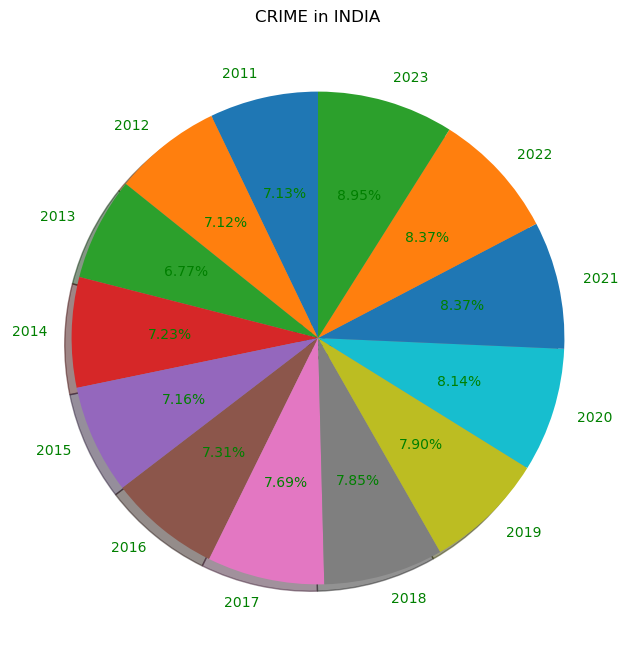

In [11]:
plt.figure(figsize=(15,8))
state = crime.groupby('YEAR')
plt.pie(state.mean()['TOTAL IPC CRIMES'],labels=state.mean().index, 
        startangle=90,shadow=True,textprops={'fontsize':10,'c':'g'},
        autopct='%0.2f%%')

plt.title('CRIME in INDIA')
plt.show()

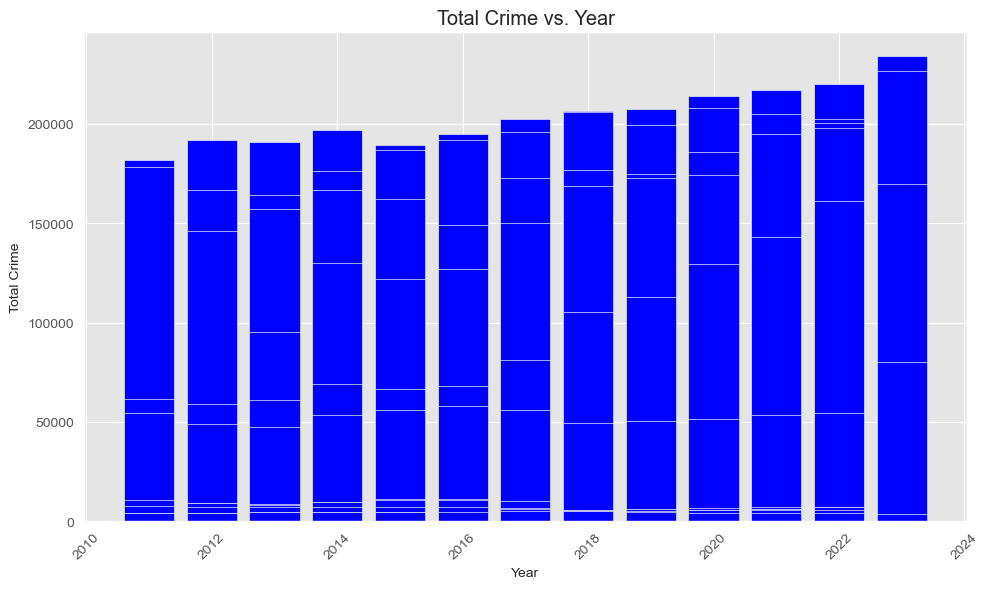

In [46]:
year = crime['YEAR']
total_crime = crime['TOTAL IPC CRIMES']

# Create a bar graph
plt.style.use('ggplot')

# Create a bar graph
plt.figure(figsize=(10, 6))
plt.bar(year, total_crime, color='blue')
plt.xlabel('Year')
plt.ylabel('Total Crime')
plt.title('Total Crime vs. Year')
plt.xticks(rotation=45)
plt.tight_layout()

# Show the plot
plt.show()

In [40]:
state_mean = crime.groupby('YEAR').mean()['TOTAL IPC CRIMES'].reset_index()
state_mean

,YEAR,TOTAL IPC CRIMES
0,2011,4942.201117
1,2012,4952.239221
2,2013,4714.615385
3,2014,5026.090535
4,2015,4972.993179
5,2016,5076.467568
6,2017,5355.781965
7,2018,5501.653088
8,2019,5531.538462
9,2020,5712.017972


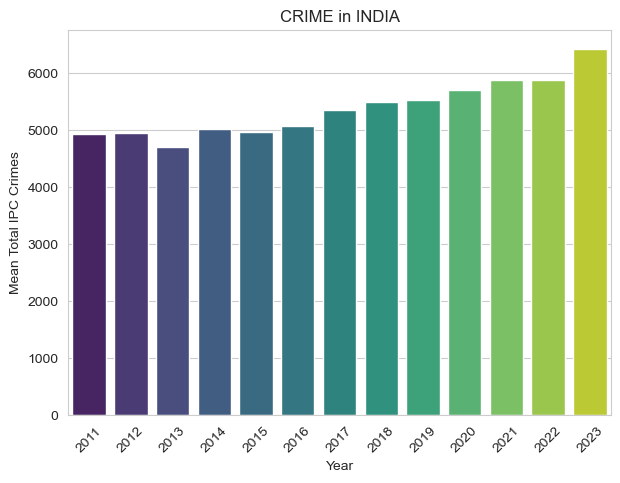

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'crime' is your DataFrame and 'TOTAL IPC CRIMES' is the column containing crime data

# Grouping by 'YEAR' and calculating mean
state_mean = crime.groupby('YEAR').mean()['TOTAL IPC CRIMES'].reset_index()

plt.figure(figsize=(7, 5))

# Plotting using seaborn
sns.set_style("whitegrid")  # Optional: Set the style

# Using pie plot in seaborn
sns.barplot(x='YEAR', y='TOTAL IPC CRIMES', data=state_mean, palette='viridis')

plt.title('CRIME in INDIA')
plt.xlabel('Year')
plt.ylabel('Mean Total IPC Crimes')
plt.xticks(rotation=45)  # Optional: Rotate x-axis labels for better readability
plt.show()


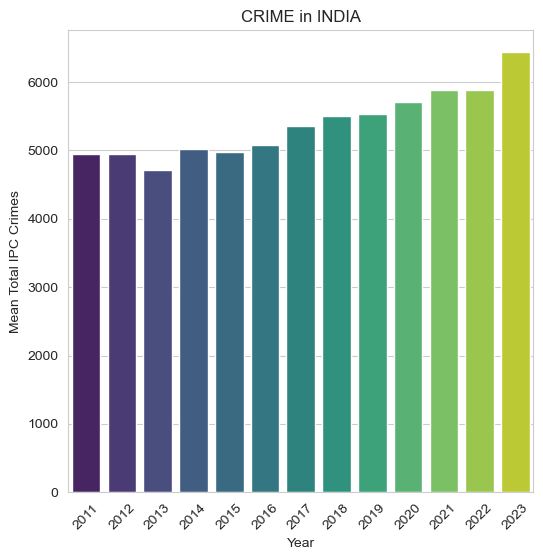

In [13]:
def yearvscrime(data):
    # Grouping by 'YEAR' and calculating mean
    state_mean = data.groupby('YEAR').mean()['TOTAL IPC CRIMES'].reset_index()

    plt.figure(figsize=(6, 6))

    # Plotting using seaborn
    sns.set_style("whitegrid")  # Optional: Set the style

    # Using bar plot in seaborn
    sns.barplot(x='YEAR', y='TOTAL IPC CRIMES', data=state_mean, palette='viridis')

    plt.title('CRIME in INDIA')
    plt.xlabel('Year')
    plt.ylabel('Mean Total IPC Crimes')
    plt.xticks(rotation=45)  # Optional: Rotate x-axis labels for better readability
    plt.show()

    # Save the plot as an image file (e.g., PNG)
    plt.savefig('plot1.png', bbox_inches='tight')  # Save the plot with tight bounding box to avoid extra whitespace
    plt.close()  # Close the plot to free up memory

    
yearvscrime(crime)

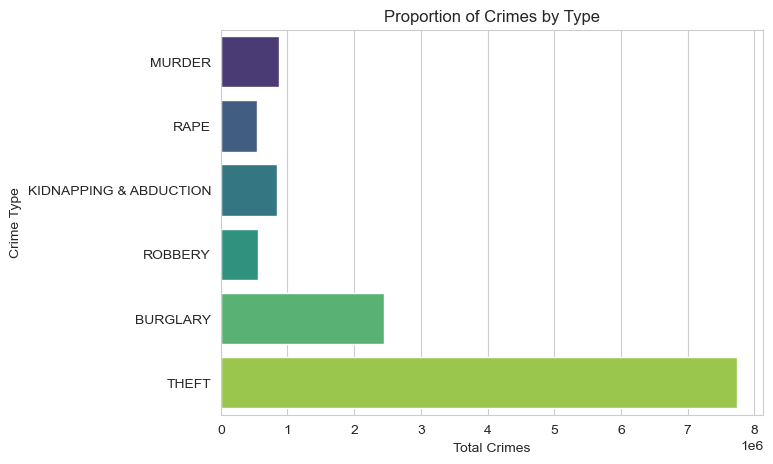

In [9]:
def man(data):
    crime_totals = data[['MURDER', 'RAPE', 'KIDNAPPING & ABDUCTION', 'ROBBERY', 'BURGLARY', 'THEFT']].sum()

    # Convert crime_totals into a DataFrame
    crime_totals_df = crime_totals.reset_index()
    crime_totals_df.columns = ['Crime Type', 'Total']

    plt.figure(figsize=(7, 5))
    sns.set_style("whitegrid")

    # Using barplot to create a pie chart-like visualization
    sns.barplot(x='Total', y='Crime Type', data=crime_totals_df, palette='viridis')

    plt.title('Proportion of Crimes by Type')
    plt.xlabel('Total Crimes')
    plt.ylabel('Crime Type')
    plt.show()

man(crime)

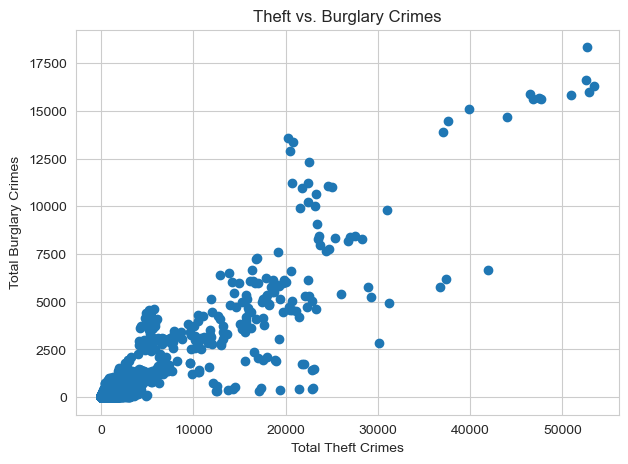

In [19]:
# Create a scatter plot of theft and burglary crimes
plt.figure(figsize=(7, 5))
plt.scatter(crime['THEFT'], crime['BURGLARY'])
plt.xlabel('Total Theft Crimes')
plt.ylabel('Total Burglary Crimes')
plt.title('Theft vs. Burglary Crimes')
plt.show()

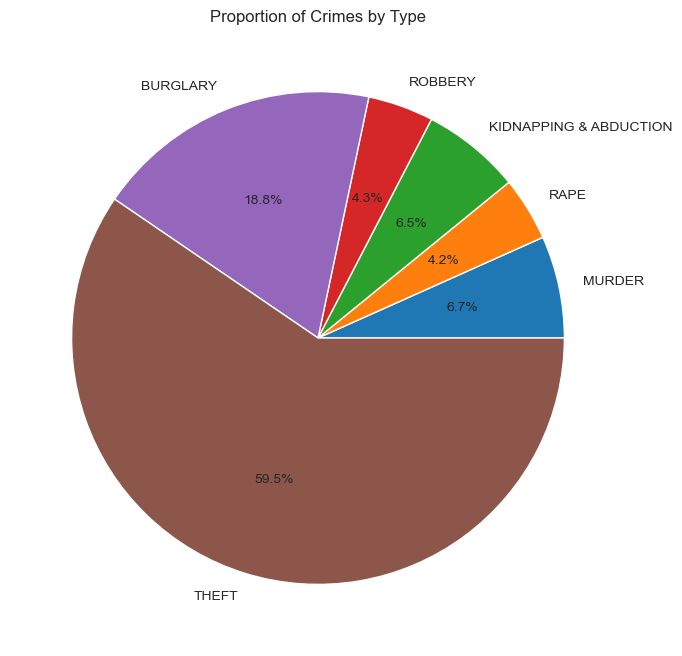

In [11]:
crime_totals = crime[['MURDER', 'RAPE', 'KIDNAPPING & ABDUCTION', 'ROBBERY', 'BURGLARY', 'THEFT']].sum()

# Create a pie chart
plt.figure(figsize=(10, 8))
plt.pie(crime_totals.values, labels=crime_totals.index, autopct='%1.1f%%')
plt.title('Proportion of Crimes by Type')
plt.show()       

In [20]:
crime.columns

Index(['STATE/UT', 'DISTRICT', 'YEAR', 'MURDER', 'ATTEMPT TO MURDER',
       'CULPABLE HOMICIDE NOT AMOUNTING TO MURDER', 'RAPE', 'CUSTODIAL RAPE',
       'OTHER RAPE', 'KIDNAPPING & ABDUCTION',
       'KIDNAPPING AND ABDUCTION OF WOMEN AND GIRLS',
       'KIDNAPPING AND ABDUCTION OF OTHERS', 'DACOITY',
       'PREPARATION AND ASSEMBLY FOR DACOITY', 'ROBBERY', 'BURGLARY', 'THEFT',
       'AUTO THEFT', 'OTHER THEFT', 'RIOTS', 'CRIMINAL BREACH OF TRUST',
       'CHEATING', 'COUNTERFIETING', 'ARSON', 'HURT/GREVIOUS HURT',
       'DOWRY DEATHS', 'ASSAULT ON WOMEN WITH INTENT TO OUTRAGE HER MODESTY',
       'INSULT TO MODESTY OF WOMEN', 'CRUELTY BY HUSBAND OR HIS RELATIVES',
       'IMPORTATION OF GIRLS FROM FOREIGN COUNTRIES',
       'CAUSING DEATH BY NEGLIGENCE', 'OTHER IPC CRIMES', 'TOTAL IPC CRIMES'],
      dtype='object')

In [74]:
result = crime[(crime['STATE/UT'] == 'Jharkhand') & (crime['DISTRICT'] == 'BOKARO') & (crime['YEAR'] <= 2023)]

In [75]:
result

,STATE/UT,DISTRICT,YEAR,MURDER,ATTEMPT TO MURDER,CULPABLE HOMICIDE NOT AMOUNTING TO MURDER,RAPE,CUSTODIAL RAPE,OTHER RAPE,KIDNAPPING & ABDUCTION,KIDNAPPING AND ABDUCTION OF WOMEN AND GIRLS,KIDNAPPING AND ABDUCTION OF OTHERS,DACOITY,PREPARATION AND ASSEMBLY FOR DACOITY,ROBBERY,BURGLARY,THEFT,AUTO THEFT,OTHER THEFT,RIOTS,CRIMINAL BREACH OF TRUST,CHEATING,COUNTERFIETING,ARSON,HURT/GREVIOUS HURT,DOWRY DEATHS,ASSAULT ON WOMEN WITH INTENT TO OUTRAGE HER MODESTY,INSULT TO MODESTY OF WOMEN,CRUELTY BY HUSBAND OR HIS RELATIVES,IMPORTATION OF GIRLS FROM FOREIGN COUNTRIES,CAUSING DEATH BY NEGLIGENCE,OTHER IPC CRIMES,TOTAL IPC CRIMES
271,Jharkhand,BOKARO,2023,47,7,0,58,0,58,78,78,0,13,0,28,159,736,219,517,139,199,145,0,0,0,15,8,0,243,0,0,1759,3634


In [ ]:
2293

<Axes: >

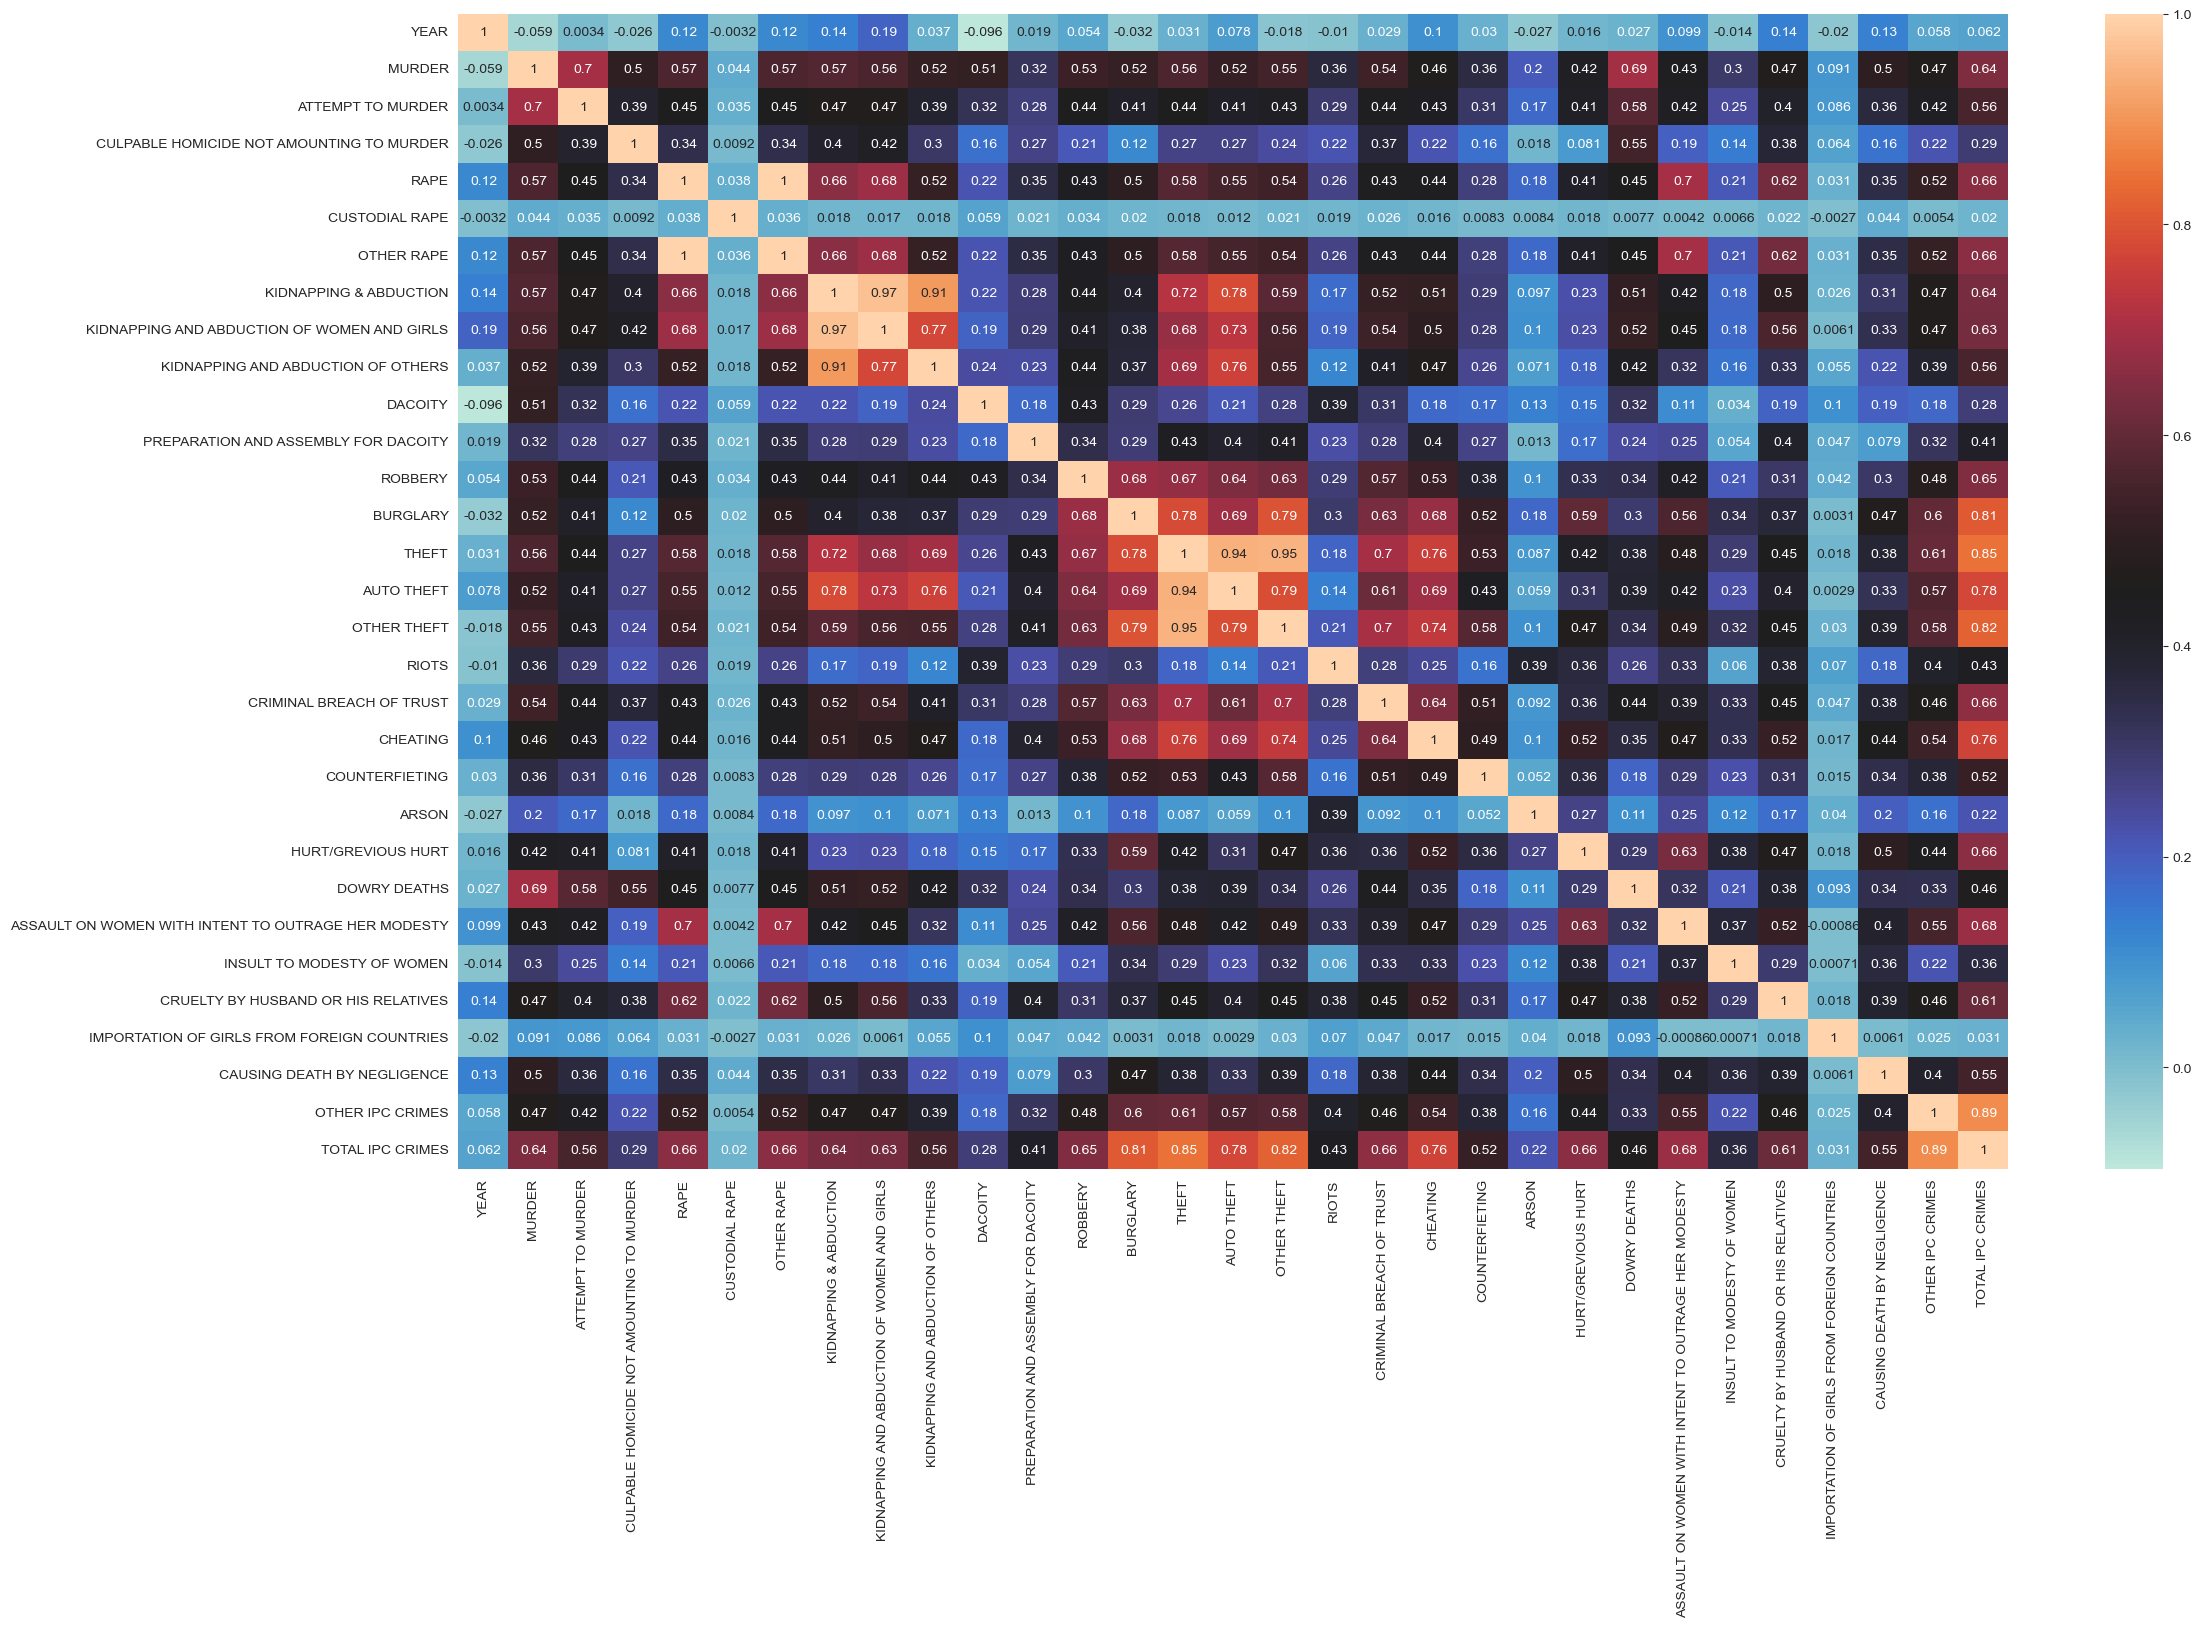

In [15]:
plt.figure(figsize=(25,15))
sns.heatmap(crime.corr(),annot=True,cmap='icefire')

<Figure size 1000x800 with 0 Axes>

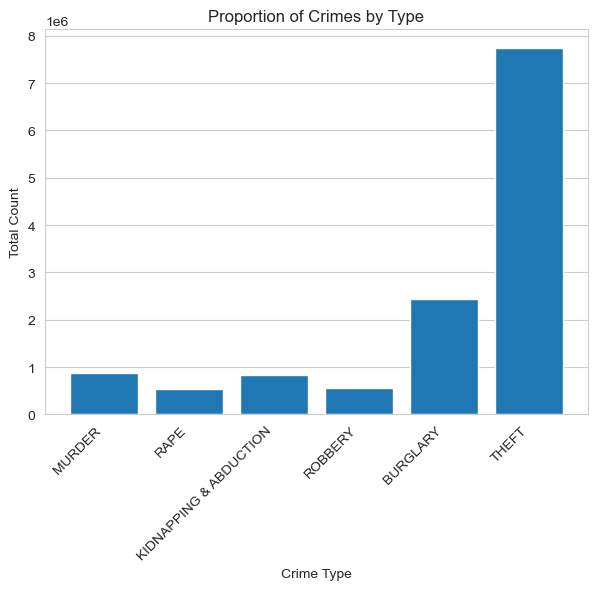

In [12]:
plt.figure(figsize=(10, 8))


plt.figure(figsize=(7, 5))

# Plotting using seaborn
sns.set_style("whitegrid")  # Optional: Set the style

# Using pie plot in seaborn
sns.barplot(x=crime_totals.index, y=crime_totals.values, data=state_mean, palette='viridis')


plt.bar(crime_totals.index, crime_totals.values)
plt.title('Proportion of Crimes by Type')
plt.xlabel('Crime Type')
plt.ylabel('Total Count')
plt.xticks(rotation=45, ha='right')  # Rotate x-axis labels for better visibility
plt.show()


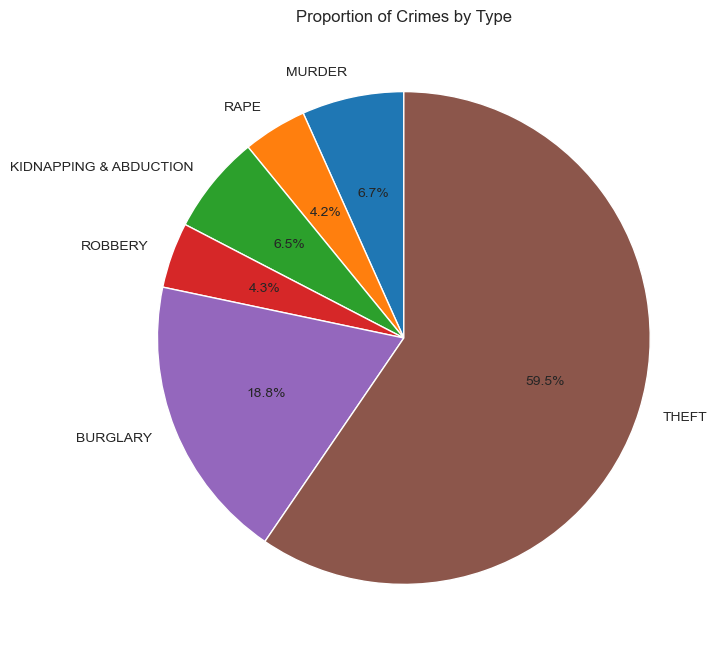

In [92]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'crime_totals' is your Series containing crime totals by type

# Set Seaborn style
sns.set_style("whitegrid")

# Create a figure and axis
fig, ax = plt.subplots(figsize=(10, 8))

# Plot the pie chart using matplotlib's pie function
pie = ax.pie(crime_totals.values, labels=crime_totals.index, autopct='%1.1f%%', startangle=90)

# Set title
ax.set_title('Proportion of Crimes by Type')

plt.show()


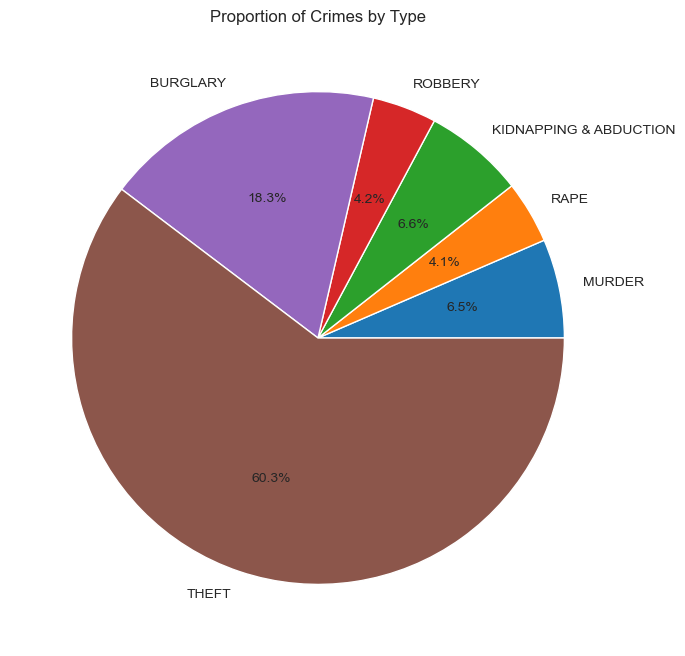

In [93]:
crime_totals = crime[['MURDER', 'RAPE', 'KIDNAPPING & ABDUCTION', 'ROBBERY', 'BURGLARY', 'THEFT']].sum()

# Create a pie chart
plt.figure(figsize=(10, 8))
plt.pie(crime_totals.values, labels=crime_totals.index, autopct='%1.1f%%')
plt.title('Proportion of Crimes by Type')
plt.show()

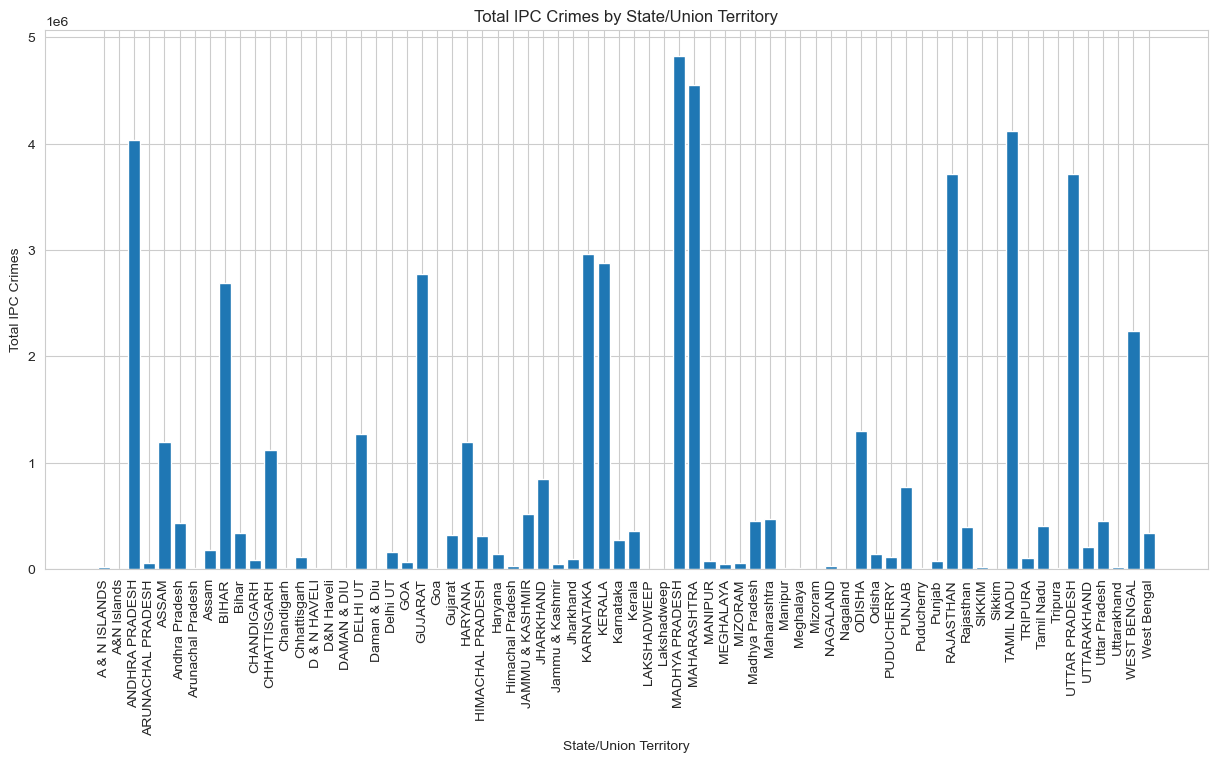

In [13]:
# Group the data by state/union territory and sum the total number of IPC crimes
state_totals = crime.groupby('STATE/UT')['TOTAL IPC CRIMES'].sum()

# Create a bar chart
plt.figure(figsize=(15, 7))
plt.bar(state_totals.index, state_totals.values)
plt.xticks(rotation=90)
plt.xlabel('State/Union Territory')
plt.ylabel('Total IPC Crimes')
plt.title('Total IPC Crimes by State/Union Territory')
plt.show()

In [ ]:
plt.figure(figsize=(25,15))
sns.heatmap(crime.corr(),annot=True,cmap='icefire')

In [95]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# Load the dataset
data = crime

# Split data into features and target variable
X = data.drop(columns=["STATE/UT", "DISTRICT", "YEAR", "TOTAL IPC CRIMES"])  # Features
y = data["TOTAL IPC CRIMES"]  # Target variable

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model training
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Model evaluation
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
print("Mean Absolute Error:", mae)

# Prediction for 2024
# Assuming you want to predict for a specific state and district
state = "Andhra Pradesh"
district = "ADILABAD"
# Filter data for the specified state and district for the year 2023
# data_subset = data[(data["STATE/UT"] == state) & (data["DISTRICT"] == district) & (data["YEAR"] == 2023)]

data_subset = data[(data["STATE/UT"] == state) & (data["DISTRICT"] == district) & (data["YEAR"] >= 2011) & (data["YEAR"] <= 2023)]
data_subset = data_subset.groupby(["STATE/UT", "DISTRICT"]).sum().reset_index()



# Extract features for prediction (excluding STATE/UT, DISTRICT, YEAR, and TOTAL IPC CRIMES)
X_pred = data_subset.drop(columns=["STATE/UT", "DISTRICT", "YEAR", "TOTAL IPC CRIMES"])
# Predict for the year 2024
predicted_crimes_2024 = model.predict(X_pred)
print("Predicted total IPC crimes for 2024:", predicted_crimes_2024)


Mean Absolute Error: 133.08806914893614
Predicted total IPC crimes for 2024: [6273.75]


In [96]:
state = "LAKSHADWEEP"
district = "LAKSHADWEEP"
# Filter data for the specified state and district for the year 2023
data_subset = data[(data["STATE/UT"] == state) & (data["DISTRICT"] == district) & (data["YEAR"] >= 2011) & (data["YEAR"] <= 2023)]
data_subset = data_subset.groupby(["STATE/UT", "DISTRICT"]).sum().reset_index()
# Extract features for prediction (excluding STATE/UT, DISTRICT, YEAR, and TOTAL IPC CRIMES)
X_pred = data_subset.drop(columns=["STATE/UT", "DISTRICT", "YEAR", "TOTAL IPC CRIMES"])
# Predict for the year 2024
predicted_crimes_2024 = model.predict(X_pred)
print("Predicted total IPC crimes for 2024:", predicted_crimes_2024)

Predicted total IPC crimes for 2024: [763.7]


Forecasted total IPC crimes for 2024 in LAKSHADWEEP - LAKSHADWEEP : 77.22743783045033


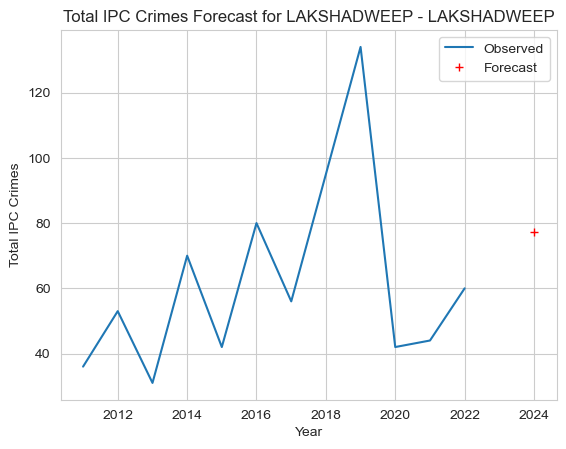

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA

# Load the dataset
# data = pd.read_csv("your_dataset.csv")
data = crime

state = "LAKSHADWEEP"
district = "LAKSHADWEEP"
aggregated_data = data[(data["STATE/UT"] == state) & (data["DISTRICT"] == district)]
aggregated_data = aggregated_data.groupby("YEAR").sum()["TOTAL IPC CRIMES"].reset_index()

# Prepare data
dates = pd.to_datetime(aggregated_data["YEAR"], format="%Y")
values = aggregated_data["TOTAL IPC CRIMES"]

# Fit ARIMA model
# Fit ARIMA model

model = ARIMA(values, order=(5,1,0))  # ARIMA(p,d,q), where (p,d,q) are the AR order, differencing order, and MA order
model_fit = model.fit()

# Make predictions for the next year (2024)
forecast = model_fit.forecast(steps=4)



# Print forecast
print("Forecasted total IPC crimes for 2024 in", state, "-", district, ":", forecast.values[0])

# Visualize the forecast
plt.plot(dates, values, label='Observed')
plt.plot(pd.to_datetime("2024", format="%Y"), forecast.values[0], 'r+', label='Forecast')
plt.title("Total IPC Crimes Forecast for " + state + " - " + district)
plt.xlabel("Year")
plt.ylabel("Total IPC Crimes")
plt.legend()
plt.show()


# model = ARIMA(values, order=(5,1,0), enforce_stationarity=False, enforce_invertibility=False)
# model_fit = model.fit()

# # Make predictions for the next year (2024)
# forecast = model_fit.forecast(steps=1)

# # Print forecast
# print("Forecasted total IPC crimes for 2024 in", state, "-", district, ":", forecast.values[0])

# # Visualize the forecast
# plt.plot(dates, values, label='Observed')
# plt.plot(pd.to_datetime("2024", format="%Y"), forecast.values[0], 'r+', label='Forecast')
# plt.title("Total IPC Crimes Forecast for " + state + " - " + district)
# plt.xlabel("Year")
# plt.ylabel("Total IPC Crimes")
# plt.legend()
# plt.show()


C:\Users\Promantus\anaconda3\lib\site-packages\statsmodels\base\model.py:604: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


Forecasted total IPC crimes for 2024 in Andhra Pradesh - ADILABAD : 6380.999999999999


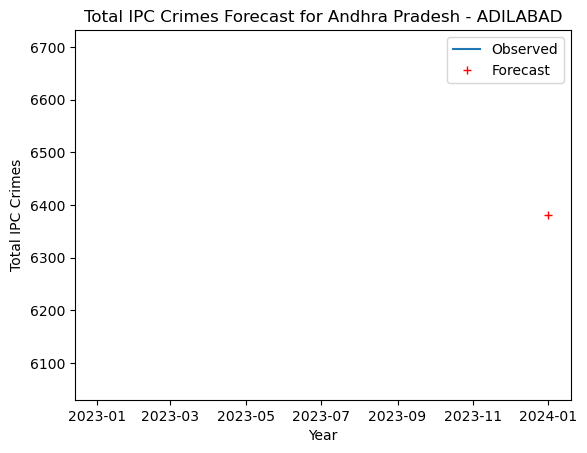

In [61]:
model = ARIMA(values, order=(5,1,0), enforce_stationarity=False, enforce_invertibility=False)
        model_fit = model.fit()

    # Make predictions for the next year (2024)
forecast = model_fit.forecast(steps=1)
state = "Andhra Pradesh"
district = "ADILABAD"
forecast_crimes(state, district)


In [7]:
df_subset = crime[['STATE/UT', 'DISTRICT']].head(5)

In [8]:
df_subset

,STATE/UT,DISTRICT
0,Andhra Pradesh,ADILABAD
1,Andhra Pradesh,ANANTAPUR
2,Andhra Pradesh,CHITTOOR
3,Andhra Pradesh,CUDDAPAH
4,Andhra Pradesh,CYBERABAD


In [23]:
df_subset.to_csv('crime_subsetdata.csv', index=False)

In [32]:
df = pd.read_csv("crime_subsetdata.csv")

In [29]:
df = pd.read_csv(r"C:\Users\Promantus\PycharmProjects\crime_subsetdata.csv")

In [30]:
df

,STATE/UT,DISTRICT
0,Andhra Pradesh,ADILABAD
1,Andhra Pradesh,ANANTAPUR
2,Andhra Pradesh,CHITTOOR
3,Andhra Pradesh,CUDDAPAH
4,Andhra Pradesh,CYBERABAD


In [68]:
import pandas as pd

# Assuming your dataset is stored in a DataFrame called 'df'
# Get unique states
unique_states = crime['STATE/UT'].unique()

# Create a dictionary to store unique districts for each state
districts_by_state = {}

# Iterate through each state
for state in unique_states:
    # Filter rows for the current state
    state_districts = crime[crime['STATE/UT'] == state]['DISTRICT']
    # Get unique districts for the current state
    unique_districts = state_districts.unique()
    # Store unique districts for the current state in the dictionary
    districts_by_state[state] = unique_districts

# Print the dictionary containing unique districts for each state
for state, districts in districts_by_state.items():
    print("State:", state)
    print("Unique Districts:", districts)
    print()


State: Andhra Pradesh
Unique Districts: ['ADILABAD' 'ANANTAPUR' 'CHITTOOR' 'CUDDAPAH' 'CYBERABAD' 'EAST GODAVARI'
 'GUNTAKAL RLY.' 'GUNTUR' 'GUNTUR URBAN' 'HYDERABAD CITY' 'KARIMNAGAR'
 'KHAMMAM' 'KRISHNA' 'KURNOOL' 'MAHABOOBNAGAR' 'MEDAK' 'NALGONDA'
 'NELLORE' 'NIZAMABAD' 'PRAKASHAM' 'RAJAHMUNDRY' 'RANGA REDDY'
 'SECUNDERABAD RLY.' 'SRIKAKULAM' 'TIRUPATHI URBAN' 'VIJAYAWADA CITY'
 'VIJAYAWADA RLY.' 'VISAKHA RURAL' 'VISAKHAPATNAM' 'VIZIANAGARAM'
 'WARANGAL' 'WARANGAL URBAN' 'WEST GODAVARI']

State: Arunachal Pradesh
Unique Districts: ['ANJAW' 'CHANGLANG' 'DIBANG VALLEY' 'K/KUMEY' 'KAMENG EAST' 'KAMENG WEST'
 'LOHIT' 'LONGDING' 'PAPUM PARE' 'RURAL' 'SIANG EAST' 'SIANG UPPER'
 'SIANG WEST' 'SUBANSIRI LOWER' 'SUBANSIRI UPPER' 'TAWANG' 'TIRAP'
 'UPPER DIBANG VALLEY']

State: Assam
Unique Districts: ['BAKSA' 'BARPETA' 'BIEO' 'BONGAIGAON' 'C.I.D.' 'CACHAR' 'CHIRANG'
 'DARRANG' 'DHEMAJI' 'DHUBRI' 'DIBRUGARH' 'G.R.P.' 'GOALPARA' 'GOLAGHAT'
 'GUWAHATI CITY' 'HAILAKANDI' 'HAMREN' 'JORHAT' 'KAMRU

In [66]:
import pandas as pd

# Assuming your dataset is stored in a DataFrame called 'df'

# Drop rows where the district is "Total" or "ZZ Total"
crime = crime[(crime['DISTRICT'] != 'TOTAL') & (crime['DISTRICT'] != 'ZZ TOTAL')]

# Now, df will contain the modified dataset without rows where the district is "Total" or "ZZ Total"



In [72]:
print(districts_by_state)

{'Andhra Pradesh': array(['ADILABAD', 'ANANTAPUR', 'CHITTOOR', 'CUDDAPAH', 'CYBERABAD',
       'EAST GODAVARI', 'GUNTAKAL RLY.', 'GUNTUR', 'GUNTUR URBAN',
       'HYDERABAD CITY', 'KARIMNAGAR', 'KHAMMAM', 'KRISHNA', 'KURNOOL',
       'MAHABOOBNAGAR', 'MEDAK', 'NALGONDA', 'NELLORE', 'NIZAMABAD',
       'PRAKASHAM', 'RAJAHMUNDRY', 'RANGA REDDY', 'SECUNDERABAD RLY.',
       'SRIKAKULAM', 'TIRUPATHI URBAN', 'VIJAYAWADA CITY',
       'VIJAYAWADA RLY.', 'VISAKHA RURAL', 'VISAKHAPATNAM',
       'VIZIANAGARAM', 'WARANGAL', 'WARANGAL URBAN', 'WEST GODAVARI'],
      dtype=object), 'Arunachal Pradesh': array(['ANJAW', 'CHANGLANG', 'DIBANG VALLEY', 'K/KUMEY', 'KAMENG EAST',
       'KAMENG WEST', 'LOHIT', 'LONGDING', 'PAPUM PARE', 'RURAL',
       'SIANG EAST', 'SIANG UPPER', 'SIANG WEST', 'SUBANSIRI LOWER',
       'SUBANSIRI UPPER', 'TAWANG', 'TIRAP', 'UPPER DIBANG VALLEY'],
      dtype=object), 'Assam': array(['BAKSA', 'BARPETA', 'BIEO', 'BONGAIGAON', 'C.I.D.', 'CACHAR',
       'CHIRANG', 'DARRANG

In [71]:
# Get unique districts for Andhra Pradesh from the districts_by_state dictionary
andhra_pradesh_districts = districts_by_state['Andhra Pradesh']

# Print the list of unique districts for Andhra Pradesh
print("Unique districts for Andhra Pradesh:", andhra_pradesh_districts)


Unique districts for Andhra Pradesh: ['ADILABAD' 'ANANTAPUR' 'CHITTOOR' 'CUDDAPAH' 'CYBERABAD' 'EAST GODAVARI'
 'GUNTAKAL RLY.' 'GUNTUR' 'GUNTUR URBAN' 'HYDERABAD CITY' 'KARIMNAGAR'
 'KHAMMAM' 'KRISHNA' 'KURNOOL' 'MAHABOOBNAGAR' 'MEDAK' 'NALGONDA'
 'NELLORE' 'NIZAMABAD' 'PRAKASHAM' 'RAJAHMUNDRY' 'RANGA REDDY'
 'SECUNDERABAD RLY.' 'SRIKAKULAM' 'TIRUPATHI URBAN' 'VIJAYAWADA CITY'
 'VIJAYAWADA RLY.' 'VISAKHA RURAL' 'VISAKHAPATNAM' 'VIZIANAGARAM'
 'WARANGAL' 'WARANGAL URBAN' 'WEST GODAVARI']


In [ ]:
{'Andhra Pradesh': ['ADILABAD', 'ANANTAPUR', 'CHITTOOR', 'CUDDAPAH', 'CYBERABAD',
       'EAST GODAVARI', 'GUNTAKAL RLY.', 'GUNTUR', 'GUNTUR URBAN',
       'HYDERABAD CITY', 'KARIMNAGAR', 'KHAMMAM', 'KRISHNA', 'KURNOOL',
       'MAHABOOBNAGAR', 'MEDAK', 'NALGONDA', 'NELLORE', 'NIZAMABAD',
       'PRAKASHAM', 'RAJAHMUNDRY', 'RANGA REDDY', 'SECUNDERABAD RLY.',
       'SRIKAKULAM', 'TIRUPATHI URBAN', 'VIJAYAWADA CITY',
       'VIJAYAWADA RLY.', 'VISAKHA RURAL', 'VISAKHAPATNAM',
       'VIZIANAGARAM', 'WARANGAL', 'WARANGAL URBAN', 'WEST GODAVARI'],
      , 'Arunachal Pradesh': array(['ANJAW', 'CHANGLANG', 'DIBANG VALLEY', 'K/KUMEY', 'KAMENG EAST',
       'KAMENG WEST', 'LOHIT', 'LONGDING', 'PAPUM PARE', 'RURAL',
       'SIANG EAST', 'SIANG UPPER', 'SIANG WEST', 'SUBANSIRI LOWER',
       'SUBANSIRI UPPER', 'TAWANG', 'TIRAP', 'UPPER DIBANG VALLEY'],
      dtype=object), 'Assam': array(['BAKSA', 'BARPETA', 'BIEO', 'BONGAIGAON', 'C.I.D.', 'CACHAR',
       'CHIRANG', 'DARRANG', 'DHEMAJI', 'DHUBRI', 'DIBRUGARH', 'G.R.P.',
       'GOALPARA', 'GOLAGHAT', 'GUWAHATI CITY', 'HAILAKANDI', 'HAMREN',
       'JORHAT', 'KAMRUP', 'KARBI ANGLONG', 'KARIMGANJ', 'KOKRAJHAR',
       'LAKHIMPUR', 'MORIGAON', 'N.C.HILLS', 'NAGAON', 'NALBARI',
       'R.P.O.', 'SIBSAGAR', 'SONITPUR', 'STF', 'TINSUKIA', 'UDALGURI'],
      dtype=object), 'Bihar': array(['ARARIA', 'ARWAL', 'AURANGABAD', 'BAGAHA', 'BANKA', 'BEGUSARAI',
       'BETTIAH', 'BHABHUA', 'BHAGALPUR', 'BHOJPUR', 'BUXAR', 'DARBHANGA',
       'GAYA', 'GOPALGANJ', 'JAMALPUR RLY.', 'JAMUI', 'JEHANABAD',
       'KATIHAR', 'KATIHAR RLY.', 'KHAGARIA', 'KISHANGANJ', 'LAKHISARAI',
       'MADHEPURA', 'MADHUBANI', 'MOTIHARI', 'MUNGER', 'MUZAFFARPUR',
       'MUZAFFARPUR RLY.', 'NALANDA', 'NAUGACHIA', 'NAWADAH', 'PATNA',
       'PATNA RLY.', 'PURNEA', 'ROHTAS', 'SAHARSA', 'SAMASTIPUR', 'SARAN',
       'SHEIKHPURA', 'SHEOHAR', 'SITAMARHI', 'SIWAN', 'SUPAUL',
       'VAISHALI'], dtype=object), 'Chhattisgarh': array(['BALOD', 'BALODA BAZAR', 'BALRAMPUR', 'BEMETARA', 'BILASPUR',
       'BIZAPUR', 'DANTEWARA', 'DHAMTARI', 'DURG', 'GARIYABAND',
       'GRP RAIPUR', 'JAGDALPUR', 'JANJGIR', 'JASHPUR', 'KABIRDHAM',
       'KANKER', 'KONDAGAON', 'KORBA', 'KORIYA', 'MAHASAMUND', 'MUNGELI',
       'NARAYANPUR', 'RAIGARH', 'RAIPUR', 'RAJNANDGAON', 'SARGUJA',
       'SUKMA', 'SURAJPUR'], dtype=object), 'Goa': array(['NORTH GOA', 'SOUTH GOA'], dtype=object), 'Gujarat': array(['AHMEDABAD COMMR.', 'AHMEDABAD RURAL', 'AHWA-DANG', 'AMRELI',
       'ANAND', 'BHARUCH', 'BHAVNAGAR', 'CID CRIME', 'DAHOD',
       'GANDHINAGAR', 'HIMATNAGAR', 'JAMNAGAR', 'JUNAGADH', 'KHEDA NORTH',
       'KUTCH (EAST(G))', 'KUTCH (WEST-BHUJ)', 'MEHSANA', 'NARMADA',
       'NAVSARI', 'PALANPUR', 'PANCHMAHAL', 'PATAN', 'PORBANDAR',
       'RAJKOT COMMR.', 'RAJKOT RURAL', 'SURAT COMMR.', 'SURAT RURAL',
       'SURENDRANAGAR', 'TAPI', 'VADODARA COMMR.', 'VADODARA RURAL',
       'VALSAD', 'W.RLY AHMEDABAD', 'W.RLY VADODARA'], dtype=object), 'Haryana': array(['AMBALA RURAL', 'AMBALA URBAN', 'BHIWANI', 'FARIDABAD',
       'FATEHABAD', 'GRP', 'GURGAON', 'HISSAR', 'I&P HARYANA', 'JHAJJAR',
       'JIND', 'KAITHAL', 'KARNAL', 'KURUKSHETRA', 'MAHENDRAGARH',
       'MEWAT', 'PALWAL', 'PANCHKULA', 'PANIPAT', 'REWARI', 'ROHTAK',
       'SIRSA', 'SONIPAT', 'YAMUNANAGAR'], dtype=object), 'Himachal Pradesh': array(['BADDIPOLICEDIST', 'BILASPUR', 'CHAMBA', 'CID', 'G.R.P.',
       'HAMIRPUR', 'KANGRA', 'KINNAUR', 'KULLU', 'LAHAUL-SPITI', 'MANDI',
       'SHIMLA', 'SIRMAUR', 'SOLAN', 'UNA'], dtype=object), 'Jammu & Kashmir': array(['ANANTNAG', 'AWANTIPORA', 'BANDIPORA', 'BARAMULLA', 'BUDGAM',
       'CRIME JAMMU', 'CRIME SRINAGAR', 'DODA', 'GANDERBAL', 'HANDWARA',
       'JAMMU', 'KARGIL', 'KATHUA', 'KISHTWAR', 'KULGAM', 'KUPWARA',
       'LEH', 'POONCH', 'PULWAMA', 'RAILWAYS JAMMU', 'RAILWAYS KASHMIR',
       'RAILWAYS KATRA', 'RAJOURI', 'RAMBAN', 'REASI', 'SAMBA', 'SHOPIAN',
       'SOPORE', 'SRINAGAR', 'UDHAMPUR'], dtype=object), 'Jharkhand': array(['BOKARO', 'CHAIBASA', 'CHATRA', 'DEOGHAR', 'DHANBAD',
       'DHANBAD RLY.', 'DUMKA', 'GARHWA', 'GIRIDIH', 'GODDA', 'GUMLA',
       'HAZARIBAGH', 'JAMSHEDPUR', 'JAMSHEDPUR RLY.', 'JAMTARA', 'KHUNTI',
       'KODERMA', 'LATEHAR', 'LOHARDAGGA', 'PAKUR', 'PALAMU', 'RAMGARH',
       'RANCHI', 'SAHEBGANJ', 'SARAIKELA', 'SIMDEGA'], dtype=object), 'Karnataka': array(['BAGALKOT', 'BANGALORE COMMR.', 'BANGALORE RURAL', 'BELGAUM',
       'BELLARY', 'BIDAR', 'BIJAPUR', 'CBPURA', 'CHAMARAJNAGAR',
       'CHICKMAGALUR', 'CHITRADURGA', 'DAKSHIN KANNADA', 'DAVANAGERE',
       'DHARWAD COMMR.', 'DHARWAD RURAL', 'GADAG', 'GULBARGA', 'HASSAN',
       'HAVERI', 'K.G.F.', 'KODAGU', 'KOLAR', 'KOPPAL', 'MANDYA',
       'MANGALORE CITY', 'MYSORE COMMR.', 'MYSORE RURAL', 'RAICHUR',
       'RAILWAYS', 'RAMANAGAR', 'SHIMOGA', 'TUMKUR', 'UDUPI',
       'UTTAR KANNADA', 'YADGIRI'], dtype=object), 'Kerala': array(['ALAPUZHA', 'ERNAKULAM COMMR.', 'ERNAKULAM RURAL', 'IDUKKI',
       'KANNUR', 'KASARGOD', 'KOLLAM COMMR.', 'KOLLAM RURAL', 'KOTTAYAM',
       'KOZHIKODE COMMR.', 'KOZHIKODE RURAL', 'MALAPPURAM', 'PALAKKAD',
       'PATHANAMTHITTA', 'RAILWAYS', 'THRISSUR COMMR.', 'THRISSUR RURAL',
       'TRIVANDRUM COMMR.', 'TRIVANDRUM RURAL', 'WAYANADU'], dtype=object), 'Madhya Pradesh': array(['AGAR', 'ALIRAJPUR', 'ANUPPUR', 'ASHOK NAGAR', 'BALAGHAT',
       'BARWANI', 'BETUL', 'BHIND', 'BHOPAL', 'BHOPAL RLY.', 'BURHANPUR',
       'CHHATARPUR', 'CHHINDWARA', 'DAMOH', 'DATIYA', 'DEWAS', 'DHAR',
       'DINDORI', 'GUNA', 'GWALIOR', 'HARDA', 'HOSHANGABAD', 'INDORE',
       'INDORE RLY.', 'JABALPUR', 'JABALPUR RLY.', 'JHABUA', 'KATNI',
       'KHANDWA', 'KHARGON', 'MANDLA', 'MANDSAUR', 'MORENA',
       'NARSINGHPUR', 'NEEMUCH', 'PANNA', 'RAISEN', 'RAJGARH', 'RATLAM',
       'REWA', 'SAGAR', 'SATNA', 'SEONI', 'SHAHDOL', 'SHAJAPUR',
       'SHEOPUR', 'SHIVPURI', 'SIDHI', 'SIHORE', 'SINGRAULI', 'TIKAMGARH',
       'UJJAIN', 'UMARIYA', 'VIDISHA'], dtype=object), 'Maharashtra': array(['AHMEDNAGAR', 'AKOLA', 'AMRAVATI COMMR.', 'AMRAVATI RURAL',
       'AURANGABAD COMMR.', 'AURANGABAD RURAL', 'BEED', 'BHANDARA',
       'BULDHANA', 'CHANDRAPUR', 'DHULE', 'GADCHIROLI', 'GONDIA',
       'HINGOLI', 'JALGAON', 'JALNA', 'KOLHAPUR', 'LATUR',
       'MUMBAI COMMR.', 'MUMBAI RLY.', 'NAGPUR COMMR.', 'NAGPUR RLY.',
       'NAGPUR RURAL', 'NANDED', 'NANDURBAR', 'NASIK COMMR.',
       'NASIK RURAL', 'NAVI MUMBAI', 'OSMANABAD', 'PARBHANI',
       'PUNE COMMR.', 'PUNE RLY.', 'PUNE RURAL', 'RAIGAD', 'RATNAGIRI',
       'SANGLI', 'SATARA', 'SINDHUDURG', 'SOLAPUR COMMR.',
       'SOLAPUR RURAL', 'THANE COMMR.', 'THANE RURAL', 'WARDHA', 'WASHIM',
       'YAVATMAL'], dtype=object), 'Manipur': array(['BISHNUPUR', 'CHANDEL', 'CHURACHANDPUR', 'CID', 'IMPHAL EAST',
       'IMPHAL WEST', 'SENAPATI', 'TAMENGLONG', 'THOUBAL', 'UKHRUL'],
      dtype=object), 'Meghalaya': array(['GARO HILLS EAST', 'GARO HILLS NORTH', 'GARO HILLS SOUTH',
       'GARO HILLS SOUTH W.', 'GARO HILLS WEST', 'JAINTIA HILLS EAST',
       'JAINTIA HILLS WEST', 'KHASI HILLS EAST', 'KHASI HILLS SOUTH W.',
       'KHASI HILLS WEST', 'RI-BHOI'], dtype=object), 'Mizoram': array(['AIZAWL', 'CHAMPHAI', 'KOLASIB', 'LAWNGTLAI', 'LUNGLEI', 'MAMIT',
       'SAIHA', 'SERCHHIP', 'SPL NARCOTIC', 'TRAFFIC PS'], dtype=object), 'Nagaland': array(['DIMAPUR', 'KIPHIRE', 'KOHIMA', 'LONGLENG', 'MOKOKCHUNG', 'MON',
       'PEREN', 'PHEK', 'TUENSANG', 'WOKHA', 'ZUNHEBOTO'], dtype=object), 'Odisha': array(['ANGUL', 'BALASORE', 'BARAGARH', 'BERHAMPUR', 'BHADRAK',
       'BOLANGIR', 'BOUDH', 'CUTTACK', 'DCP BBSR', 'DCP CTC', 'DEOGARH',
       'DHENKANAL', 'GAJAPATI', 'GANJAM', 'JAGATSINGHPUR', 'JAJPUR',
       'JHARSUGUDA', 'KALAHANDI', 'KANDHAMAL', 'KENDRAPARA', 'KEONJHAR',
       'KHURDA', 'KORAPUT', 'MALKANGIR', 'MAYURBHANJ', 'NAYAGARH',
       'NOWRANGPUR', 'NUAPADA', 'PURI', 'RAYAGADA', 'ROURKELA',
       'SAMBALPUR', 'SONEPUR', 'SRP(CUTTACK)', 'SRP(ROURKELA)',
       'SUNDARGARH'], dtype=object), 'Punjab': array(['AMRITSAR RURAL', 'BARNALA', 'BATALA', 'BHATINDA', 'CP AMRITSAR',
       'CP JALANDHAR', 'CP LUDHIANA', 'FARIDKOT', 'FATEHGARH SAHIB',
       'FAZILKA', 'FEROZPUR', 'G.R.P', 'GURDASPUR', 'HOSHIARPUR',
       'JALANDHAR RURAL', 'KAPURTHALA', 'KHANNA', 'LUDHIANA RURAL',
       'MANSA', 'MOGA', 'MUKTSAR', 'PATHANKOT', 'PATIALA', 'ROPAR',
       'SANGRUR', 'SAS NGR', 'SBS NAGAR', 'TARN TARAN'], dtype=object), 'Rajasthan': array(['AJMER', 'ALWAR', 'BANSWARA', 'BARAN', 'BARMER', 'BHARATPUR',
       'BHILWARA', 'BIKANER', 'BUNDI', 'CHITTORGARH', 'CHURU', 'DAUSA',
       'DHOLPUR', 'DISCOM', 'DUNGARPUR', 'G.R.P.AJMER', 'G.R.P.JODHPUR',
       'GANGANAGAR', 'HANUMANGARH', 'JAIPUR EAST', 'JAIPUR NORTH',
       'JAIPUR RURAL', 'JAIPUR SOUTH', 'JAIPUR WEST', 'JAISALMER',
       'JALORE', 'JHALAWAR', 'JHUNJHUNU', 'JODHPUR EAST', 'JODHPUR RURAL',
       'JODHPUR WEST', 'KARAULI', 'KOTA CITY', 'KOTA RURAL', 'NAGAUR',
       'PALI', 'PRATAPGARH', 'RAJSAMAND', 'SAWAI MADHOPUR', 'SIKAR',
       'SIROHI', 'TONK', 'UDAIPUR'], dtype=object), 'Sikkim': array(['EAST', 'NORTH', 'SOUTH', 'WEST'], dtype=object), 'Tamil Nadu': array(['ARIYALUR', 'CHENNAI', 'CHENNAI RLY.', 'COIMBATORE RURAL',
       'COIMBATORE URBAN', 'CUDDALORE', 'DHARMAPURI', 'DINDIGUL', 'ERODE',
       'KANCHIPURAM', 'KANYAKUMARI', 'KARUR', 'KRISHNAGIRI',
       'MADURAI RURAL', 'MADURAI URBAN', 'NAGAPATTINAM', 'NAMAKKAL',
       'NILGIRIS', 'PERAMBALUR', 'PUDUKOTTAI', 'RAMNATHAPURAM',
       'SALEM RURAL', 'SALEM URBAN', 'SIVAGANGAI', 'THANJAVUR', 'THENI',
       'THIRUNELVELI RURAL', 'THIRUNELVELI URBAN', 'THIRUVALLUR',
       'THIRUVANNAMALAI', 'THIRUVARUR', 'THOOTHUGUDI', 'TIRUPPUR',
       'TRICHY RLY.', 'TRICHY RURAL', 'TRICHY URBAN', 'VELLORE',
       'VILLUPURAM', 'VIRUDHUNAGAR'], dtype=object), 'Tripura': array(['DHALAI', 'GOMATI', 'GRP', 'KHOWAI', 'NORTH', 'SIPAHIJALA',
       'SOUTH', 'UNAKOTI', 'WEST'], dtype=object), 'Uttar Pradesh': array(['AGRA', 'ALIGARH', 'ALLAHABAD', 'AMBEDKAR NAGAR', 'AMETHI',
       'AMROHA', 'AURAIYA', 'AZAMGARH', 'BADAUN', 'BAGHPAT', 'BAHRAICH',
       'BALLIA', 'BALRAMPUR', 'BANDA', 'BARABANKI', 'BAREILLY', 'BASTI',
       'BIJNOR', 'BULANDSHAHAR', 'CHANDOLI', 'CHITRAKOOT DHAM', 'DEORIA',
       'ETAH', 'ETAWAH', 'FAIZABAD', 'FATEHGARH', 'FATEHPUR', 'FIROZABAD',
       'G.R.P.', 'GAUTAMBUDH NAGAR', 'GHAZIABAD', 'GHAZIPUR', 'GONDA',
       'GORAKHPUR', 'HAMIRPUR', 'HAPUR', 'HARDOI', 'HATHRAS', 'JALAUN',
       'JAUNPUR', 'JHANSI', 'KANNAUJ', 'KANPUR DEHAT', 'KANPUR NAGAR',
       'KASGANJ', 'KAUSHAMBI', 'KHIRI', 'KUSHI NAGAR', 'LALITPUR',
       'LUCKNOW', 'MAHARAJGANJ', 'MAHOBA', 'MAINPURI', 'MATHURA', 'MAU',
       'MEERUT', 'MIRZAPUR', 'MORADABAD', 'MUZAFFARNAGAR', 'PILIBHIT',
       'PRATAPGARH', 'RAIBAREILLY', 'RAMPUR', 'SAHARANPUR', 'SAMBHAL',
       'SANT KABIRNAGAR', 'SHAHJAHANPUR', 'SHAMLI', 'SHRAWASTI',
       'SIDHARTHNAGAR', 'SITAPUR', 'SONBHADRA', 'ST.RAVIDASNAGAR',
       'SULTANPUR', 'UNNAO', 'VARANASI'], dtype=object), 'Uttarakhand': array(['ALMORA', 'BAGESHWAR', 'CHAMOLI', 'CHAMPAWAT', 'DEHRADUN',
       'HARIDWAR', 'NAINITAL', 'PAURI GARHWAL', 'PITHORAGARH',
       'RUDRA PRAYAG', 'TEHRI GARHWAL', 'UDHAMSINGH NAGAR', 'UTTARKASHI'],
      dtype=object), 'West Bengal': array(['24 PARGANAS NORTH', '24 PARGANAS SOUTH', 'ASANSOL', 'BANKURA',
       'BDN CP', 'BIRBHUM', 'BKP CP', 'BURDWAN', 'COOCHBEHAR',
       'DAKSHIN DINAJPUR', 'DARJEELING', 'HOOGHLY', 'HOWRAH',
       'HOWRAH CITY', 'HOWRAH G.R.P.', 'JALPAIGURI', 'JHARGRAM',
       'KHARAGPUR G.R.P.', 'KOLKATA', 'MALDA', 'MURSHIDABAD', 'NADIA',
       'PASCHIM MIDNAPUR', 'PURAB MIDNAPUR', 'PURULIA', 'SEALDAH G.R.P.',
       'SILIGURI G.R.P.', 'SILIGURI_PC', 'UTTAR DINAJPUR'], dtype=object), 'A&N Islands': array(['CAR', 'NORTH', 'SOUTH'], dtype=object), 'Chandigarh': array(['CHANDIGARH'], dtype=object), 'D&N Haveli': array(['D&N HAVELI'], dtype=object), 'Daman & Diu': array(['DAMAN', 'DIU'], dtype=object), 'Delhi UT': array(['CAW', 'CENTRAL', 'CRIME BRANCH', 'EAST', 'EOW', 'GRP(RLY)',
       'IGI AIRPORT', 'METRO RAIL', 'NEW DELHI', 'NORTH', 'NORTH-EAST',
       'NORTH-WEST', 'OUTER', 'SOUTH', 'SOUTH-EAST', 'SOUTH-WEST', 'STF',
       'WEST'], dtype=object), 'Lakshadweep': array(['LAKSHADWEEP'], dtype=object), 'Puducherry': array(['KARAIKAL', 'PUDUCHERRY'], dtype=object), 'ANDHRA PRADESH': array(['ADILABAD', 'ANANTAPUR', 'CHITTOOR', 'CUDDAPAH', 'CYBERABAD',
       'EAST GODAVARI', 'GUNTAKAL RLY.', 'GUNTUR', 'GUNTUR URBAN',
       'HYDERABAD CITY', 'KARIMNAGAR', 'KHAMMAM', 'KRISHNA', 'KURNOOL',
       'MAHABOOBNAGAR', 'MEDAK', 'NALGONDA', 'NELLORE', 'NIZAMABAD',
       'PRAKASHAM', 'RAJAHMUNDRY', 'RANGA REDDY', 'SECUNDERABAD RLY.',
       'SRIKAKULAM', 'TIRUPATHI URBAN', 'VIJAYAWADA CITY',
       'VIJAYAWADA RLY.', 'VISAKHA RURAL', 'VISAKHAPATNAM',
       'VIZIANAGARAM', 'WARANGAL', 'WARANGAL URBAN', 'WEST GODAVARI',
       'VIJAYAWADA'], dtype=object), 'ARUNACHAL PRADESH': array(['ANJAW', 'CHANGLANG', 'DIBANG VALLEY', 'K/KUMEY', 'KAMENG EAST',
       'KAMENG WEST', 'LOHIT', 'PAPUM PARE', 'RURAL', 'SIANG EAST',
       'SIANG UPPER', 'SIANG WEST', 'SUBANSIRI LOWER', 'SUBANSIRI UPPER',
       'TAWANG', 'TIRAP', 'UPPER DIBANG VALLEY'], dtype=object), 'ASSAM': array(['BAKSA', 'BARPETA', 'BIEO', 'BONGAIGAON', 'C.I.D.', 'CACHAR',
       'CHIRANG', 'DARRANG', 'DHEMAJI', 'DHUBRI', 'DIBRUGARH', 'G.R.P.',
       'GOALPARA', 'GOLAGHAT', 'GUWAHATI CITY', 'HAILAKANDI', 'HAMREN',
       'JORHAT', 'KAMRUP', 'KARBI ANGLONG', 'KARIMGANJ', 'KOKRAJHAR',
       'LAKHIMPUR', 'MORIGAON', 'N.C.HILLS', 'NAGAON', 'NALBARI',
       'R.P.O.', 'SIBSAGAR', 'SONITPUR', 'TINSUKIA', 'UDALGURI', 'BASKA'],
      dtype=object), 'BIHAR': array(['ARARIA', 'ARWAL', 'AURANGABAD', 'BAGAHA', 'BANKA', 'BEGUSARAI',
       'BETTIAH', 'BHABHUA', 'BHAGALPUR', 'BHOJPUR', 'BUXAR', 'DARBHANGA',
       'GAYA', 'GOPALGANJ', 'JAMALPUR RLY.', 'JAMUI', 'JEHANABAD',
       'KATIHAR', 'KATIHAR RLY.', 'KHAGARIA', 'KISHANGANJ', 'LAKHISARAI',
       'MADHEPURA', 'MADHUBANI', 'MOTIHARI', 'MUNGER', 'MUZAFFARPUR',
       'MUZAFFARPUR RLY.', 'NALANDA', 'NAUGACHIA', 'NAWADAH', 'PATNA',
       'PATNA RLY.', 'PURNEA', 'ROHTAS', 'SAHARSA', 'SAMASTIPUR', 'SARAN',
       'SHEIKHPURA', 'SHEOHAR', 'SITAMARHI', 'SIWAN', 'SUPAUL',
       'VAISHALI'], dtype=object), 'CHHATTISGARH': array(['BALOD', 'BALODA BAZAR', 'BALRAMPUR', 'BEMETARA', 'BILASPUR',
       'BIZAPUR', 'DANTEWARA', 'DHAMTARI', 'DURG', 'GARIYABAND',
       'GRP RAIPUR', 'JAGDALPUR', 'JANJGIR', 'JASHPUR', 'KABIRDHAM',
       'KANKER', 'KONDAGAON', 'KORBA', 'KORIYA', 'MAHASAMUND', 'MUNGELI',
       'NARAYANPUR', 'RAIGARH', 'RAIPUR', 'RAJNANDGAON', 'SARGUJA',
       'SUKMA', 'SURAJPUR', 'KAWARDHA'], dtype=object), 'GOA': array(['NORTH GOA', 'SOUTH GOA'], dtype=object), 'GUJARAT': array(['AHMEDABAD COMMR.', 'AHMEDABAD RURAL', 'AHWA-DANG', 'AMRELI',
       'ANAND', 'BHARUCH', 'BHAVNAGAR', 'CID CRIME', 'DAHOD',
       'GANDHINAGAR', 'HIMATNAGAR', 'JAMNAGAR', 'JUNAGADH', 'KHEDA NORTH',
       'KUTCH (EAST(G))', 'KUTCH (WEST-BHUJ)', 'MEHSANA', 'NARMADA',
       'NAVSARI', 'PALANPUR', 'PANCHMAHAL', 'PATAN', 'PORBANDAR',
       'RAJKOT COMMR.', 'RAJKOT RURAL', 'SURAT COMMR.', 'SURAT RURAL',
       'SURENDRANAGAR', 'TAPI', 'VADODARA COMMR.', 'VADODARA RURAL',
       'VALSAD', 'W.RLY AHMEDABAD', 'W.RLY VADODARA', 'KUTCH', 'W.RLY'],
      dtype=object), 'HARYANA': array(['AMBALA RURAL', 'AMBALA URBAN', 'BHIWANI', 'FARIDABAD',
       'FATEHABAD', 'GRP', 'GURGAON', 'HISSAR', 'JHAJJAR', 'JIND',
       'KAITHAL', 'KARNAL', 'KURUKSHETRA', 'MAHENDRAGARH', 'MEWAT',
       'PALWAL', 'PANCHKULA', 'PANIPAT', 'REWARI', 'ROHTAK', 'SIRSA',
       'SONIPAT', 'YAMUNANAGAR', 'AMBALA'], dtype=object), 'HIMACHAL PRADESH': array(['BADDIPOLICEDIST', 'BILASPUR', 'CHAMBA', 'CID', 'G.R.P.',
       'HAMIRPUR', 'KANGRA', 'KINNAUR', 'KULLU', 'LAHAUL-SPITI', 'MANDI',
       'SHIMLA', 'SIRMAUR', 'SOLAN', 'UNA'], dtype=object), 'JAMMU & KASHMIR': array(['ANANTNAG', 'AWANTIPORA', 'BANDIPORA', 'BARAMULLA', 'BUDGAM',
       'CRIME JAMMU', 'CRIME SRINAGAR', 'DODA', 'GANDERBAL', 'HANDWARA',
       'JAMMU', 'KARGIL', 'KATHUA', 'KISHTWAR', 'KULGAM', 'KUPWARA',
       'LEH', 'POONCH', 'PULWAMA', 'RAILWAYS JAMMU', 'RAILWAYS KASHMIR',
       'RAILWAYS KATRA', 'RAJOURI', 'RAMBAN', 'REASI', 'SAMBA', 'SHOPIAN',
       'SOPORE', 'SRINAGAR', 'UDHAMPUR', 'CRIME KASHMIR', 'RAILWAYS',
       'RAILWAYS KMR', 'BORDER DISTRICT', 'BORDER'], dtype=object), 'JHARKHAND': array(['BOKARO', 'CHAIBASA', 'CHATRA', 'DEOGHAR', 'DHANBAD',
       'DHANBAD RLY.', 'DUMKA', 'GARHWA', 'GIRIDIH', 'GODDA', 'GUMLA',
       'HAZARIBAGH', 'JAMSHEDPUR', 'JAMSHEDPUR RLY.', 'JAMTARA', 'KHUNTI',
       'KODERMA', 'LATEHAR', 'LOHARDAGGA', 'PAKUR', 'PALAMU', 'RAMGARH',
       'RANCHI', 'SAHEBGANJ', 'SARAIKELA', 'SIMDEGA'], dtype=object), 'KARNATAKA': array(['BAGALKOT', 'BANGALORE COMMR.', 'BANGALORE RURAL', 'BELGAUM',
       'BELLARY', 'BIDAR', 'BIJAPUR', 'CBPURA', 'CHAMARAJNAGAR',
       'CHICKMAGALUR', 'CHITRADURGA', 'DAKSHIN KANNADA', 'DAVANAGERE',
       'DHARWAD COMMR.', 'DHARWAD RURAL', 'GADAG', 'GULBARGA', 'HASSAN',
       'HAVERI', 'K.G.F.', 'KODAGU', 'KOLAR', 'KOPPAL', 'MANDYA',
       'MANGALORE CITY', 'MYSORE COMMR.', 'MYSORE RURAL', 'RAICHUR',
       'RAILWAYS', 'RAMANAGAR', 'SHIMOGA', 'TUMKUR', 'UDUPI',
       'UTTAR KANNADA', 'YADGIRI'], dtype=object), 'KERALA': array(['ALAPUZHA', 'ERNAKULAM COMMR.', 'ERNAKULAM RURAL', 'IDUKKI',
       'KANNUR', 'KASARGOD', 'KOLLAM COMMR.', 'KOLLAM RURAL', 'KOTTAYAM',
       'KOZHIKODE COMMR.', 'KOZHIKODE RURAL', 'MALAPPURAM', 'PALAKKAD',
       'PATHANAMTHITTA', 'RAILWAYS', 'THRISSUR COMMR.', 'THRISSUR RURAL',
       'TRIVANDRUM COMMR.', 'TRIVANDRUM RURAL', 'WAYANADU', 'KOLLAM',
       'THRISSUR', 'CBCID', 'ERNAKULAM', 'KOZHIKODE', 'TRIVANDRUM'],
      dtype=object), 'MADHYA PRADESH': array(['ALIRAJPUR', 'ANUPPUR', 'ASHOK NAGAR', 'BALAGHAT', 'BARWANI',
       'BETUL', 'BHIND', 'BHOPAL', 'BHOPAL RLY.', 'BURHANPUR',
       'CHHATARPUR', 'CHHINDWARA', 'DAMOH', 'DATIYA', 'DEWAS', 'DHAR',
       'DINDORI', 'GUNA', 'GWALIOR', 'HARDA', 'HOSHANGABAD', 'INDORE',
       'INDORE RLY.', 'JABALPUR', 'JABALPUR RLY.', 'JHABUA', 'KATNI',
       'KHANDWA', 'KHARGON', 'MANDLA', 'MANDSAUR', 'MORENA',
       'NARSINGHPUR', 'NEEMUCH', 'PANNA', 'RAISEN', 'RAJGARH', 'RATLAM',
       'REWA', 'SAGAR', 'SATNA', 'SEONI', 'SHAHDOL', 'SHAJAPUR',
       'SHEOPUR', 'SHIVPURI', 'SIDHI', 'SIHORE', 'SINGRAULI', 'TIKAMGARH',
       'UJJAIN', 'UMARIYA', 'VIDISHA'], dtype=object), 'MAHARASHTRA': array(['AHMEDNAGAR', 'AKOLA', 'AMRAVATI COMMR.', 'AMRAVATI RURAL',
       'AURANGABAD COMMR.', 'AURANGABAD RURAL', 'BEED', 'BHANDARA',
       'BULDHANA', 'CHANDRAPUR', 'DHULE', 'GADCHIROLI', 'GONDIA',
       'HINGOLI', 'JALGAON', 'JALNA', 'KOLHAPUR', 'LATUR',
       'MUMBAI COMMR.', 'MUMBAI RLY.', 'NAGPUR COMMR.', 'NAGPUR RLY.',
       'NAGPUR RURAL', 'NANDED', 'NANDURBAR', 'NASIK COMMR.',
       'NASIK RURAL', 'NAVI MUMBAI', 'OSMANABAD', 'PARBHANI',
       'PUNE COMMR.', 'PUNE RLY.', 'PUNE RURAL', 'RAIGAD', 'RATNAGIRI',
       'SANGLI', 'SATARA', 'SINDHUDURG', 'SOLAPUR COMMR.',
       'SOLAPUR RURAL', 'THANE COMMR.', 'THANE RURAL', 'WARDHA', 'WASHIM',
       'YAVATMAL', 'MUMBAI'], dtype=object), 'MANIPUR': array(['BISHNUPUR', 'CHANDEL', 'CHURACHANDPUR', 'CID', 'IMPHAL EAST',
       'IMPHAL WEST', 'SENAPATI', 'TAMENGLONG', 'THOUBAL', 'UKHRUL',
       'IMPHAL(EAST)', 'IMPHAL(WEST)'], dtype=object), 'MEGHALAYA': array(['GARO HILLS EAST', 'GARO HILLS SOUTH', 'GARO HILLS WEST',
       'JAINTIA HILLS', 'KHASI HILLS EAST', 'KHASI HILLS WEST', 'RI-BHOI'],
      dtype=object), 'MIZORAM': array(['AIZAWL', 'CHAMPHAI', 'KOLASIB', 'LAWNGTLAI', 'LUNGLEI', 'MAMIT',
       'SAIHA', 'SERCHHIP'], dtype=object), 'NAGALAND': array(['DIMAPUR', 'KIPHIRE', 'KOHIMA', 'LONGLENG', 'MOKOKCHUNG', 'MON',
       'PEREN', 'PHEK', 'TUENSANG', 'WOKHA', 'ZUNHEBOTO'], dtype=object), 'ODISHA': array(['ANGUL', 'BALASORE', 'BARAGARH', 'BERHAMPUR', 'BHADRAK',
       'BOLANGIR', 'BOUDH', 'CUTTACK', 'DCP BBSR', 'DCP CTC', 'DEOGARH',
       'DHENKANAL', 'GAJAPATI', 'GANJAM', 'JAGATSINGHPUR', 'JAJPUR',
       'JHARSUGUDA', 'KALAHANDI', 'KANDHAMAL', 'KENDRAPARA', 'KEONJHAR',
       'KHURDA', 'KORAPUT', 'MALKANGIR', 'MAYURBHANJ', 'NAYAGARH',
       'NOWRANGPUR', 'NUAPADA', 'PURI', 'RAYAGADA', 'ROURKELA',
       'SAMBALPUR', 'SONEPUR', 'SRP(CUTTACK)', 'SRP(ROURKELA)',
       'SUNDARGARH'], dtype=object), 'PUNJAB': array(['AMRITSAR RURAL', 'BARNALA', 'BATALA', 'BHATINDA', 'CP AMRITSAR',
       'CP JALANDHAR', 'CP LUDHIANA', 'FARIDKOT', 'FATEHGARH SAHIB',
       'FAZILKA', 'FEROZPUR', 'G.R.P', 'GURDASPUR', 'HOSHIARPUR',
       'JALANDHAR RURAL', 'KAPURTHALA', 'KHANNA', 'LUDHIANA RURAL',
       'MANSA', 'MOGA', 'MUKTSAR', 'PATHANKOT', 'PATIALA', 'ROPAR',
       'SANGRUR', 'SAS NGR', 'SBS NAGAR', 'TARN TARAN', 'AMRITSAR',
       'JALANDHAR', 'LUDHIANA', 'JAGRAON', 'NAWAN SHAHR', 'MAJITHA',
       'FEROZEPUR'], dtype=object), 'RAJASTHAN': array(['AJMER', 'ALWAR', 'BANSWARA', 'BARAN', 'BARMER', 'BHARATPUR',
       'BHILWARA', 'BIKANER', 'BUNDI', 'CHITTORGARH', 'CHURU', 'DAUSA',
       'DHOLPUR', 'DUNGARPUR', 'G.R.P.AJMER', 'G.R.P.JODHPUR',
       'GANGANAGAR', 'HANUMANGARH', 'JAIPUR EAST', 'JAIPUR NORTH',
       'JAIPUR RURAL', 'JAIPUR SOUTH', 'JAIPUR WEST', 'JAISALMER',
       'JALORE', 'JHALAWAR', 'JHUNJHUNU', 'JODHPUR EAST', 'JODHPUR RURAL',
       'JODHPUR WEST', 'KARAULI', 'KOTA CITY', 'KOTA RURAL', 'NAGAUR',
       'PALI', 'PRATAPGARH', 'RAJSAMAND', 'SAWAI MADHOPUR', 'SIKAR',
       'SIROHI', 'TONK', 'UDAIPUR', 'JODHPUR CITY', 'G.R.P. AJMER',
       'G.R.P. JODHPUR', 'G.R.P.', 'JAIPUR', 'JODHPUR', 'KOTA'],
      dtype=object), 'SIKKIM': array(['EAST', 'NORTH', 'SOUTH', 'WEST'], dtype=object), 'TAMIL NADU': array(['ARIYALUR', 'CHENNAI', 'CHENNAI RLY.', 'COIMBATORE RURAL',
       'COIMBATORE URBAN', 'CUDDALORE', 'DHARMAPURI', 'DINDIGUL', 'ERODE',
       'KANCHIPURAM', 'KANYAKUMARI', 'KARUR', 'KRISHNAGIRI',
       'MADURAI RURAL', 'MADURAI URBAN', 'NAGAPATTINAM', 'NAMAKKAL',
       'NILGIRIS', 'PERAMBALUR', 'PUDUKOTTAI', 'RAMNATHAPURAM',
       'SALEM RURAL', 'SALEM URBAN', 'SIVAGANGAI', 'THANJAVUR', 'THENI',
       'THIRUNELVELI RURAL', 'THIRUNELVELI URBAN', 'THIRUVALLUR',
       'THIRUVANNAMALAI', 'THIRUVARUR', 'THOOTHUGUDI', 'TIRUPPUR',
       'TRICHY RLY.', 'TRICHY RURAL', 'TRICHY URBAN', 'VELLORE',
       'VILLUPURAM', 'VIRUDHUNAGAR', 'CHENNAISUBURBAN', 'VILUPPURAM',
       'CHENGAI'], dtype=object), 'TRIPURA': array(['DHALAI', 'GOMATI', 'GRP', 'KHOWAI', 'NORTH', 'SIPAHIJALA',
       'SOUTH', 'UNAKOTI', 'WEST', 'G.R.P.'], dtype=object), 'UTTAR PRADESH': array(['AGRA', 'ALIGARH', 'ALLAHABAD', 'AMBEDKAR NAGAR', 'AURAIYA',
       'AZAMGARH', 'BADAUN', 'BAGHPAT', 'BAHRAICH', 'BALLIA', 'BALRAMPUR',
       'BANDA', 'BARABANKI', 'BAREILLY', 'BASTI', 'BHIM NAGAR', 'BIJNOR',
       'BULANDSHAHAR', 'CHANDOLI', 'CHITRAKOOT DHAM', 'CSM NAGAR',
       'DEORIA', 'ETAH', 'ETAWAH', 'FAIZABAD', 'FATEHGARH', 'FATEHPUR',
       'FIROZABAD', 'G.R.P.', 'GAUTAMBUDH NAGAR', 'GHAZIABAD', 'GHAZIPUR',
       'GONDA', 'GORAKHPUR', 'HAMIRPUR', 'HARDOI', 'HATHRAS', 'J.P.NAGAR',
       'JALAUN', 'JAUNPUR', 'JHANSI', 'KANNAUJ', 'KANPUR NAGAR',
       'KANSHIRAM NAGAR', 'KAUSHAMBI', 'KHIRI', 'KUSHI NAGAR', 'LALITPUR',
       'LUCKNOW', 'MAHARAJGANJ', 'MAHOBA', 'MAINPURI', 'MATHURA', 'MAU',
       'MEERUT', 'MIRZAPUR', 'MORADABAD', 'MUZAFFARNAGAR',
       'PANCHSHIL NAGAR', 'PILIBHIT', 'PRABUDDH NAGAR', 'PRATAPGARH',
       'RAIBAREILLY', 'RAMABAI NAGAR', 'RAMPUR', 'SAHARANPUR',
       'SANT KABIRNAGAR', 'SHAHJAHANPUR', 'SHRAWASTI', 'SIDHARTHNAGAR',
       'SITAPUR', 'SONBHADRA', 'ST.RAVIDASNAGAR', 'SULTANPUR', 'UNNAO',
       'VARANASI', 'KANPUR DEHAT'], dtype=object), 'UTTARAKHAND': array(['ALMORA', 'BAGESHWAR', 'CHAMOLI', 'CHAMPAWAT', 'DEHRADUN',
       'HARIDWAR', 'NAINITAL', 'PAURI GARHWAL', 'PITHORAGARH',
       'RUDRA PRAYAG', 'TEHRI GARHWAL', 'UDHAMSINGH NAGAR', 'UTTARKASHI'],
      dtype=object), 'WEST BENGAL': array(['24 PARGANAS NORTH', '24 PARGANAS SOUTH', 'ASANSOL', 'BANKURA',
       'BDN CP', 'BIRBHUM', 'BKP CP', 'BURDWAN', 'COOCHBEHAR',
       'DAKSHIN DINAJPUR', 'DARJEELING', 'HOOGHLY', 'HOWRAH',
       'HOWRAH CITY', 'HOWRAH G.R.P.', 'JALPAIGURI', 'JHARGRAM',
       'KHARAGPUR G.R.P.', 'KOLKATA', 'MALDA', 'MURSHIDABAD', 'NADIA',
       'PASCHIM MIDNAPUR', 'PURAB MIDNAPUR', 'PURULIA', 'SEALDAH G.R.P.',
       'SILIGURI G.R.P.', 'SILIGURI_PC', 'UTTAR DINAJPUR', 'MIDNAPUR'],
      dtype=object), 'A & N ISLANDS': array(['CAR', 'NORTH', 'SOUTH', 'ANDAMAN', 'NICOBAR', 'A and N ISLANDS'],
      dtype=object), 'CHANDIGARH': array(['CHANDIGARH'], dtype=object), 'D & N HAVELI': array(['D and N HAVELI'], dtype=object), 'DAMAN & DIU': array(['DAMAN', 'DIU'], dtype=object), 'DELHI UT': array(['CAW', 'CENTRAL', 'CRIME BRANCH', 'DELHI UT TOTAL', 'EAST', 'EOW',
       'GRP(RLY)', 'IGI AIRPORT', 'NEW DELHI', 'NORTH', 'NORTH-EAST',
       'NORTH-WEST', 'OUTER', 'SOUTH', 'SOUTH-EAST', 'SOUTH-WEST', 'STF',
       'WEST', 'G.R.P.(RLY)', 'SPL CELL', 'I.G.I. AIRPORT', 'NORTH EAST',
       'NORTH WEST', 'S.T.F.', 'SOUTH WEST'], dtype=object), 'LAKSHADWEEP': array(['LAKSHADWEEP'], dtype=object), 'PUDUCHERRY': array(['KARAIKAL', 'PUDUCHERRY', 'PONDICHERRY'], dtype=object)}

In [74]:
for state, districts in districts_by_state.items():
    print(state)
    print(districts)

Andhra Pradesh
['ADILABAD' 'ANANTAPUR' 'CHITTOOR' 'CUDDAPAH' 'CYBERABAD' 'EAST GODAVARI'
 'GUNTAKAL RLY.' 'GUNTUR' 'GUNTUR URBAN' 'HYDERABAD CITY' 'KARIMNAGAR'
 'KHAMMAM' 'KRISHNA' 'KURNOOL' 'MAHABOOBNAGAR' 'MEDAK' 'NALGONDA'
 'NELLORE' 'NIZAMABAD' 'PRAKASHAM' 'RAJAHMUNDRY' 'RANGA REDDY'
 'SECUNDERABAD RLY.' 'SRIKAKULAM' 'TIRUPATHI URBAN' 'VIJAYAWADA CITY'
 'VIJAYAWADA RLY.' 'VISAKHA RURAL' 'VISAKHAPATNAM' 'VIZIANAGARAM'
 'WARANGAL' 'WARANGAL URBAN' 'WEST GODAVARI']
Arunachal Pradesh
['ANJAW' 'CHANGLANG' 'DIBANG VALLEY' 'K/KUMEY' 'KAMENG EAST' 'KAMENG WEST'
 'LOHIT' 'LONGDING' 'PAPUM PARE' 'RURAL' 'SIANG EAST' 'SIANG UPPER'
 'SIANG WEST' 'SUBANSIRI LOWER' 'SUBANSIRI UPPER' 'TAWANG' 'TIRAP'
 'UPPER DIBANG VALLEY']
Assam
['BAKSA' 'BARPETA' 'BIEO' 'BONGAIGAON' 'C.I.D.' 'CACHAR' 'CHIRANG'
 'DARRANG' 'DHEMAJI' 'DHUBRI' 'DIBRUGARH' 'G.R.P.' 'GOALPARA' 'GOLAGHAT'
 'GUWAHATI CITY' 'HAILAKANDI' 'HAMREN' 'JORHAT' 'KAMRUP' 'KARBI ANGLONG'
 'KARIMGANJ' 'KOKRAJHAR' 'LAKHIMPUR' 'MORIGAON' 'N.C.HILLS

In [ ]:
import logging
from flask import Flask, request, jsonify

app = Flask(__name__)

# Configure logging
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

@app.route('/generalUser', methods=['POST'])
def general_user_backend():
    try:
        # Retrieve data from request
        state = request.form.get('State')
        district = request.form.get('District')
        year = request.form.get('Year')

        # Validate input
        if not (state and district and year):
            raise ValueError("State, District, and Year are required.")

        year = int(year)
        if year < 2011 or year > 2023:
            raise ValueError("Year must be between 2011 and 2023.")

        # Filter data for the specified state, district, and year range
        filtered_data = data[
            (data["STATE/UT"] == state) & 
            (data["DISTRICT"] == district) & 
            (data["YEAR"] >= 2011) & 
            (data["YEAR"] <= year)
        ]

        if filtered_data.empty:
            raise ValueError("No data found for the specified parameters.")

        # Group and sum data
        grouped_data = filtered_data.groupby(["STATE/UT", "DISTRICT"]).sum().reset_index()

        # Prepare features for prediction
        X_pred = grouped_data.drop(columns=["STATE/UT", "DISTRICT", "YEAR", "TOTAL IPC CRIMES"])

        # Predict for the year 2024
        predicted_crimes_2024 = loaded_model.predict(X_pred)
        predicted_crimes_2024 = int(predicted_crimes_2024)

        # Log prediction
        logger.info(f"Predicted total IPC crimes for {state}'s {district} in 2024: {predicted_crimes_2024}")

        # Construct response
        response = {
            'message': f"Total IPC crimes for {state}'s {district} in 2024 would be : {predicted_crimes_2024}"
        }

        return jsonify(response), 201

    except Exception as e:
        logger.error(f"An error occurred: {str(e)}")
        return jsonify({'error': str(e)}), 400

if __name__ == '__main__':
    app.run(debug=True)


In [14]:
import statsmodels.api as sm

In [15]:
crime_df = pd.read_csv(r"C:\Users\Promantus\PycharmProjects\pythonProject\data\crime_2023.csv", parse_dates=['YEAR'], index_col=['YEAR'])

# Resample data to yearly frequency
crime_yearly = crime_df.resample('Y').sum()

In [16]:
model = sm.tsa.ARIMA(crime_yearly['TOTAL IPC CRIMES'], order=(1,1,1))
results = model.fit()
print(results.summary())

                               SARIMAX Results                                
Dep. Variable:       TOTAL IPC CRIMES   No. Observations:                   13
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -167.382
Date:                Fri, 15 Mar 2024   AIC                            340.764
Time:                        10:47:09   BIC                            342.219
Sample:                    12-31-2011   HQIC                           340.226
                         - 12-31-2023                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.7077      0.243     -2.917      0.004      -1.183      -0.232
ma.L1          0.7513      0.225      3.336      0.001       0.310       1.193
sigma2      1.683e+10    2.5e-11   6.73e+20      0.0

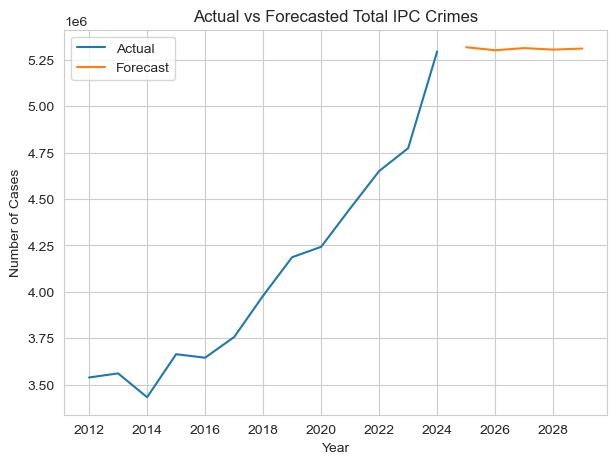

In [18]:


# Resample data to yearly frequency
crime_yearly = crime_df.resample('Y').sum()
plt.figure(figsize=(7,5))
forecast = results.predict(start=len(crime_yearly), end=len(crime_yearly)+4)
plt.plot(crime_yearly.index, crime_yearly['TOTAL IPC CRIMES'], label='Actual')
plt.plot(forecast.index, forecast, label='Forecast')
plt.title('Actual vs Forecasted Total IPC Crimes')
plt.xlabel('Year')
plt.ylabel('Number of Cases')
plt.legend()
plt.show()

In [23]:
data = crime